# 03-2. 관측값 추정: 추가 실험과 RWIS 보간 개선

03(관측값 추정 모델)의 3장. 03-1의 후보 외에 다른 고전 머신러닝 기법, MLP 구조, 앙상블 방식, 잔차 공간 보간, 지점 특성 변수를
같은 조건(핵심 변수 12개, 지점 단위 7묶음 교차검증, 지점별 RMSE 평균)으로 비교한다. 3-6에서는 RWIS 노면온도 보간을
"AWS·ASOS 밑그림 + RWIS 지문·그날의 오차" 구조로 고쳐(B3) 최종 앙상블을 확정한다.

03 구성: 03-1 후보 모델·교차검증(1~2장) · **03-2 추가 실험·RWIS 보간 개선(3장)** · 03-3 검증 지점 평가·시각화·저장(4~6장)

- 입력: 02-2의 지점·구간 변수, 02-1의 AWS 10분 자료, 02-3의 ERA5-Land(`era5_10min.parquet`), 03-1의 교차검증 예측·설정 (`estimation_oof.parquet`, `estimation_cv.json`)
- 출력: 실험 결과 표 (`data/results/estimation_model_comparison.csv`, `estimation_mlp_architectures.csv`,
  `estimation_ensembles.csv`, `estimation_site_correction.csv`, `estimation_interp_*.csv`),
  B3 추정값·설정과 최종 앙상블 구성 (`data/processed/estimation_b3.parquet`, `segment_b3.parquet`, `estimation_final.json`,
  `model/road_temp_b3.json`, 03-3·05-1에서 사용)

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]  # notebooks/<단계 폴더>/ 에서 실행
sys.path.insert(0, str(ROOT))

from src import config

In [2]:
import json
import time
import warnings

import geopandas as gpd
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler
from matplotlib import font_manager
from scipy.spatial.distance import cdist
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

for font in ["NanumGothic", "Malgun Gothic", "AppleGothic"]:
    if any(f.name == font for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font
        break
plt.rcParams.update({
    "axes.unicode_minus": False,
    "axes.prop_cycle": cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                     "#e87ba4", "#008300", "#4a3aa7", "#e34948"]),
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100, "lines.linewidth": 1.5,
})

for d in [config.RESULT_DIR, config.MODEL_DIR, config.FIGURE_DIR]:
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
TARGET = "rst"  # 노면온도

In [3]:
sf = pd.read_parquet(config.PROCESSED_DIR / "station_features.parquet")
stations = pd.read_parquet(config.PROCESSED_DIR / "stations.parquet").set_index("stn")
FEATURES = json.load(open(config.PROCESSED_DIR / "features.json", encoding="utf-8"))["features"]

# 03-1에서 정한 설정
cv = json.load(open(config.PROCESSED_DIR / "estimation_cv.json", encoding="utf-8"))
CORE, LGB_PARAMS, best_iter = cv["core"], cv["lgb_params"], cv["best_iter"]

def split_holdout(df):
    """검증 지점(config.HOLDOUT_STATIONS)을 학습 데이터에서 분리한다 (03-1의 1장과 같음)."""
    is_holdout = df["stn"].isin(config.HOLDOUT_STATIONS)
    return df[~is_holdout].reset_index(drop=True), df[is_holdout].reset_index(drop=True)


train_all, holdout = split_holdout(sf)
train = train_all.dropna(subset=[TARGET])

# 03-1의 학습 지점 교차검증 예측
oof = pd.read_parquet(config.PROCESSED_DIR / "estimation_oof.parquet")
assert oof["stn"].equals(train_all["stn"]) and oof["time"].equals(train_all["time"])
oof = oof.drop(columns=["stn", "time"])
folds = cv["folds"]

def make_ridge():
    """Ridge(핵심) (03-1의 2장과 같음)."""
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1.0))


print(f"학습 지점 {train_all['stn'].nunique()}곳, 검증 지점 {holdout['stn'].nunique()}곳, 교차검증 예측 {list(oof.columns)}")

학습 지점 14곳, 검증 지점 3곳, 교차검증 예측 ['B0 보간 기온', 'B1 주변 노면온도', 'B2 기온+노면편차', 'LightGBM(전체)', 'LightGBM(핵심)', 'Ridge(핵심)', '앙상블']


In [4]:
# 묶음 누수 방지 (03-1의 2장과 같음): 주변 RWIS 변수를 원천 지점에 맞춰 다시 만든다
WET_STATES = [2, 3, 4, 11, 12, 13, 14, 15]  # 젖은 노면 상태 (02-2의 3-3과 같음)
NBR_FEATURES = ["nbr_rst", "nbr_anom", "rst_phys", "nbr_ice", "nbr_ice_3h", "nbr_wet", "nbr_snow", "nbr_dist"]
_g = gpd.GeoSeries(gpd.points_from_xy(stations["lon"], stations["lat"]), crs=4326).to_crs(5179)
STN_XY = pd.DataFrame({"x": _g.x.to_numpy(), "y": _g.y.to_numpy()}, index=stations.index)
TRAIN_STNS = sorted(train_all["stn"].unique())
N_T = len(train_all) // len(TRAIN_STNS)
assert (train_all["stn"].to_numpy() == np.repeat(TRAIN_STNS, N_T)).all()
PERIOD_ID = np.searchsorted([pd.Timestamp(s) for s, _ in config.PERIODS[1:]], train_all["time"].iloc[:N_T].to_numpy(),
                            side="right")
_wide = lambda col: train_all[col].to_numpy("float32").reshape(len(TRAIN_STNS), N_T)
_state = _wide("state")
NBR_SRC = {"rst": _wide("rst"), "ta": _wide("ta"),
           "ice": np.where(np.isnan(_state), np.nan, np.isin(_state, config.ICE_STATE_CODES)).astype("float32"),
           "wet": np.where(np.isnan(_state), np.nan, np.isin(_state, WET_STATES)).astype("float32"),
           "snow": np.where(np.isnan(_state), np.nan, _state == 3).astype("float32")}


def idw_weights(tgt_xy, src_xy, k=3, power=2, exclude=None):
    """(대상 x 원천) IDW 가중치. exclude[i]=j 이면 대상 i에서 원천 j를 뺀다 (02-2의 3-2와 같음)."""
    d = cdist(tgt_xy, src_xy)
    if exclude is not None:
        for i, j in enumerate(exclude):
            if j >= 0:
                d[i, j] = np.inf
    w = np.zeros_like(d)
    nearest = np.argsort(d, axis=1)[:, :k]
    rows = np.arange(len(d))[:, None]
    w[rows, nearest] = 1.0 / np.maximum(d[rows, nearest], 50.0) ** power
    return w.astype("float32")


def idw_apply(w, values):
    """values: (원천 x 시각). 결측 원천은 그 시각 가중치에서 빠진다 (02-2의 3-2와 같음)."""
    ok = ~np.isnan(values)
    num = w @ np.where(ok, values, 0)
    den = w @ ok.astype("float32")
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(den > 0, num / den, np.nan).astype("float32")


def neighbor_features(src_stns):
    """학습 지점 14곳의 주변 RWIS 변수를 원천 src_stns만으로 다시 만든다. 원천인 지점은 자기 자신을 뺀다.

    반환: train_all과 같은 행 순서의 DataFrame (NBR_FEATURES).
    """
    src = [TRAIN_STNS.index(s) for s in src_stns]
    exclude = [src.index(i) if i in src else -1 for i in range(len(TRAIN_STNS))]
    tgt_xy, src_xy = STN_XY.loc[TRAIN_STNS].to_numpy(), STN_XY.loc[list(src_stns)].to_numpy()
    w = idw_weights(tgt_xy, src_xy, exclude=exclude)
    elev, lapse = stations.loc[TRAIN_STNS, "elev"].to_numpy("float32"), np.float32(0.0065)
    f = {"nbr_rst": idw_apply(w, NBR_SRC["rst"][src] + lapse * elev[src, None]) - lapse * elev[:, None],
         "nbr_anom": idw_apply(w, NBR_SRC["rst"][src] - NBR_SRC["ta"][src])}
    f["rst_phys"] = NBR_SRC["ta"] + f["nbr_anom"]
    for v in ["ice", "wet", "snow"]:
        f[f"nbr_{v}"] = idw_apply(w, NBR_SRC[v][src])
    f["nbr_ice_3h"] = np.concatenate([pd.DataFrame(f["nbr_ice"][:, PERIOD_ID == p].T).rolling(18, min_periods=1).max()
                                      .to_numpy("float32").T for p in np.unique(PERIOD_ID)], axis=1)
    d = cdist(tgt_xy, src_xy)
    for i, j in enumerate(exclude):
        if j >= 0:
            d[i, j] = np.inf
    f["nbr_dist"] = np.repeat((d.min(axis=1) / 1000)[:, None], N_T, axis=1).astype("float32")
    return pd.DataFrame({c: f[c].ravel() for c in NBR_FEATURES}, index=train_all.index)


FOLD_NBR = [neighbor_features([s for s in TRAIN_STNS if s not in v]) for v in folds]


def fold_frame(k):
    """k번째 묶음을 검증할 때 쓰는 train_all. 주변 RWIS 변수만 그 묶음의 학습 지점 원천으로 바뀐다."""
    return train_all.assign(**FOLD_NBR[k])


# 원천을 학습 지점 14곳 전체로 하면 02-2의 변수와 같아야 한다
check = neighbor_features(TRAIN_STNS)
print("02-2 주변 RWIS 변수와의 최대 차이:", float(np.nanmax(np.abs(check.to_numpy() - train_all[NBR_FEATURES].to_numpy()))))


02-2 주변 RWIS 변수와의 최대 차이: 0.0


## 3. 고전 ML 기법 비교와 추가 실험

2절의 후보 외에 다른 고전 머신러닝 기법, MLP 구조, 앙상블 방식, 지점 특성 변수를 **같은 조건**(핵심 변수 12개, 지점 단위 7묶음 교차검증,
지점별 RMSE 평균)으로 비교한다. 03-1과 같이 묶음마다 주변 RWIS 변수를 다시 만들어 묶음 누수를 막는다. 목적은 세 가지이다.

1. LightGBM이 이 문제에 가장 좋은 방법인지 확인한다.
2. 성능을 실제로 제한하는 요인이 모델 형태인지, 자료(지점 수·지점 특성)인지 가린다.
3. 주변 RWIS 노면 관측과 AWS·ASOS 기상을 합치는 방식(공간 보간)을 개선한다 (3-6).

### 3-1. 다른 고전 기법

| 기법 | 설정 | 성격 |
|------|------|------|
| Ridge 상호작용(2차) | 변수 쌍의 곱 66개 추가 + Ridge(α=10) | 계수가 시간대·일사에 따라 변하는 선형 모델 |
| 스플라인 GAM | 변수별 3차 스플라인(매듭 6개) + Ridge | 변수마다 비선형, 변수 간은 가법 |
| kNN | 표준화 변수 공간의 가까운 200개 평균 (학습 15만 행 표본) | 비모수 국소 평균 |
| Random Forest | 150그루, 잎 최소 500행, 그루마다 20% 표본 | 배깅 트리 |
| Extra Trees | 150그루, 잎 최소 500행, 무작위 분할 | 배깅 트리 (분산 더 작음) |
| MLP(64-32) | 은닉층 64-32 (ReLU), L2 1e-3, 조기 종료 (학습 20만 행 표본) | 신경망 |
| LightGBM 선형트리 | 잎마다 선형식을 두는 LightGBM | 부스팅 + 선형 외삽 |
| XGBoost | 깊이 4, 학습률 0.03, 반복 횟수는 LightGBM과 같은 방식으로 선택 | 부스팅 |
| Ridge + 잔차 IDW | Ridge 예측 + 학습 지점의 같은 시각 잔차를 가까운 3곳 IDW로 보간 | 회귀 크리깅의 단순 근사 |

In [5]:
import itertools

import xgboost as xgb
from scipy.optimize import minimize
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import PolynomialFeatures, SplineTransformer


def imputed(*steps):
    return make_pipeline(SimpleImputer(strategy="median"), *steps)


SK_MODELS = {
    "Ridge 상호작용(2차)": lambda: imputed(StandardScaler(), PolynomialFeatures(2, interaction_only=True, include_bias=False),
                                       Ridge(alpha=10.0)),
    "스플라인 GAM": lambda: imputed(SplineTransformer(n_knots=6, extrapolation="linear"), Ridge(alpha=1.0)),
    "kNN(k=200)": lambda: imputed(StandardScaler(), KNeighborsRegressor(n_neighbors=200, n_jobs=-1)),
    "Random Forest": lambda: imputed(RandomForestRegressor(n_estimators=150, min_samples_leaf=500, max_features=0.5,
                                                           max_samples=0.2, n_jobs=-1, random_state=SEED)),
    "Extra Trees": lambda: imputed(ExtraTreesRegressor(n_estimators=150, min_samples_leaf=500, max_features=0.7,
                                                       max_samples=0.2, bootstrap=True, n_jobs=-1, random_state=SEED)),
    "MLP(64-32)": lambda: imputed(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, batch_size=512,
                                                                 early_stopping=True, max_iter=80, random_state=SEED)),
}
SUBSAMPLE = {"kNN(k=200)": 150_000, "MLP(64-32)": 200_000}
XGB_JOBS = 4  # 이 환경(WSL2)에서는 XGBoost 스레드를 늘릴수록 오히려 느려진다
BOOST_MODELS = {
    "LightGBM 선형트리": ("lgb", dict(LGB_PARAMS["LightGBM(핵심)"], linear_tree=True, linear_lambda=1.0)),
    "XGBoost": ("xgb", dict(n_estimators=600, learning_rate=0.03, max_depth=4, min_child_weight=5000, subsample=0.7,
                            colsample_bytree=0.7, reg_lambda=5.0, tree_method="hist", n_jobs=XGB_JOBS,
                            random_state=SEED, eval_metric="rmse")),
}


def fit_sk(name, df):
    d = df.dropna(subset=[TARGET])
    n = SUBSAMPLE.get(name)
    if n and len(d) > n:
        d = d.sample(n, random_state=SEED)
    return SK_MODELS[name]().fit(d[CORE], d[TARGET])


def boost_fit(kind, params, tr, va=None):
    """va가 있으면 검증 곡선도 돌려준다."""
    tr = tr.dropna(subset=[TARGET])
    if kind == "lgb":
        rec, kw = {}, {}
        if va is not None:
            va = va.dropna(subset=[TARGET])
            kw = dict(eval_set=[(va[CORE], va[TARGET])], eval_metric="rmse", callbacks=[lgb.record_evaluation(rec)])
        m = lgb.LGBMRegressor(**params).fit(tr[CORE], tr[TARGET], **kw)
        return m, (rec["valid_0"]["rmse"] if va is not None else None)
    kw = {}
    if va is not None:
        va = va.dropna(subset=[TARGET])
        kw = dict(eval_set=[(va[CORE], va[TARGET])], verbose=False)
    m = xgb.XGBRegressor(**params).fit(tr[CORE], tr[TARGET], **kw)
    return m, (m.evals_result()["validation_0"]["rmse"] if va is not None else None)


def boost_predict(kind, m, X, n):
    return m.predict(X, num_iteration=n) if kind == "lgb" else m.predict(X, iteration_range=(0, n))


def residual_idw(src_df, src_pred, dst_df, k=3, power=2):
    """src 지점의 같은 시각 잔차(관측 - 예측)를 가까운 k곳 IDW로 dst 지점에 보간한다."""
    res = pd.DataFrame({"stn": src_df["stn"].values, "time": src_df["time"].values,
                        "r": src_df[TARGET].values - src_pred}).pivot(index="time", columns="stn", values="r")
    out = pd.Series(0.0, index=dst_df.index)
    for stn, idx in dst_df.groupby("stn").groups.items():
        dist = pd.Series({s: haversine_km(stations.loc[stn], stations.loc[s]) for s in res.columns}).sort_values()
        R = res[dist.index].reindex(dst_df.loc[idx, "time"].values).to_numpy()
        w = 1 / np.maximum(dist.to_numpy(), 1.0) ** power
        use = ~np.isnan(R) & (np.cumsum(~np.isnan(R), axis=1) <= k)
        num, den = np.where(use, np.nan_to_num(R) * w, 0).sum(1), np.where(use, w, 0).sum(1)
        out[idx] = np.where(den > 0, num / np.where(den > 0, den, 1), 0.0)
    return out.to_numpy()


def haversine_km(a, b):
    la1, lo1, la2, lo2 = map(np.radians, [a["lat"], a["lon"], b["lat"], b["lon"]])
    h = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(h))


cmp_time = {}
for name in SK_MODELS:
    t0, pred = time.time(), pd.Series(np.nan, index=train_all.index)
    for k, val_stns in enumerate(folds):
        f = fold_frame(k)
        rows = f["stn"].isin(val_stns)
        pred[rows] = fit_sk(name, f[~rows]).predict(f.loc[rows, CORE])
    oof[name], cmp_time[name] = pred, time.time() - t0
    print(f"{name}: {cmp_time[name]:.0f}s")
for name, (kind, params) in BOOST_MODELS.items():
    t0, models_k, curves = time.time(), [], []
    for k, val_stns in enumerate(folds):
        f = fold_frame(k)
        rows = f["stn"].isin(val_stns)
        m, c = boost_fit(kind, params, f[~rows], f[rows])
        models_k.append(m)
        curves.append(c)
    best_iter[name] = int(np.argmin(np.mean(curves, axis=0))) + 1
    pred = pd.Series(np.nan, index=train_all.index)
    for k, (m, val_stns) in enumerate(zip(models_k, folds)):
        f = fold_frame(k)
        rows = f["stn"].isin(val_stns)
        pred[rows] = boost_predict(kind, m, f.loc[rows, CORE], best_iter[name])
    oof[name], cmp_time[name] = pred, time.time() - t0
    print(f"{name}: 최적 반복 {best_iter[name]}회, {time.time() - t0:.0f}s")
t0, pred = time.time(), pd.Series(np.nan, index=train_all.index)
for k, val_stns in enumerate(folds):
    f = fold_frame(k)
    rows = f["stn"].isin(val_stns)
    src = f[~rows].dropna(subset=[TARGET])
    m = make_ridge().fit(src[CORE], src[TARGET])
    pred[rows] = m.predict(f.loc[rows, CORE]) + residual_idw(src, m.predict(src[CORE]), f[rows])
oof["Ridge + 잔차 IDW"], cmp_time["Ridge + 잔차 IDW"] = pred, time.time() - t0

Ridge 상호작용(2차): 5s


스플라인 GAM: 8s


kNN(k=200): 46s


Random Forest: 221s


Extra Trees: 14s


MLP(64-32): 171s


LightGBM 선형트리: 최적 반복 253회, 89s


XGBoost: 최적 반복 402회, 26s


지점별 RMSE를 짝지어 비교한다. "LightGBM보다 나은 지점 수"는 14곳 중 그 방법의 RMSE가 LightGBM(핵심)보다 작은 지점 수,
"차이 ± 표준오차"는 지점별 RMSE 차이(방법 - LightGBM 핵심)의 평균과 표준오차이다. 검증 지점 성능은 참고로만 붙인다.

In [6]:
def per_station_rmse(df, preds, mask=None):
    m = np.ones(len(df), bool) if mask is None else np.asarray(mask)
    e2 = (preds.sub(df[TARGET], axis=0) ** 2)[m]
    return np.sqrt(e2.groupby(df.loc[m, "stn"]).mean())


CMP_METHODS = ["B1 주변 노면온도", "B2 기온+노면편차", "Ridge(핵심)", "Ridge 상호작용(2차)", "스플라인 GAM", "kNN(k=200)",
               "Random Forest", "Extra Trees", "MLP(64-32)", "LightGBM(핵심)", "LightGBM 선형트리", "XGBoost",
               "LightGBM(전체)", "Ridge + 잔차 IDW", "앙상블"]
hr = train_all["time"].dt.hour
st_rmse = per_station_rmse(train_all, oof[CMP_METHODS])
diff = st_rmse.sub(st_rmse["LightGBM(핵심)"], axis=0)
cmp_table = pd.DataFrame({
    "CV RMSE": st_rmse.mean(),
    "밤(19~06시)": per_station_rmse(train_all, oof[CMP_METHODS], (hr >= 19) | (hr <= 6)).mean(),
    "낮(10~15시)": per_station_rmse(train_all, oof[CMP_METHODS], (hr >= 10) & (hr <= 15)).mean(),
    "노면 ≤ 2°C": per_station_rmse(train_all, oof[CMP_METHODS], train_all[TARGET] <= 2).mean(),
    "LightGBM보다 나은 지점 수": (st_rmse.lt(st_rmse["LightGBM(핵심)"], axis=0)).sum(),
    "LightGBM 대비 차이": diff.mean(), "표준오차": diff.std() / np.sqrt(len(diff)),
    "학습 시간(s)": pd.Series(cmp_time),
})

# 검증 지점 (참고): 학습 지점 14곳 전체로 학습
tr_full = train.copy()
ho_cmp = pd.DataFrame(index=holdout.index)
ho_cmp["B1 주변 노면온도"], ho_cmp["B2 기온+노면편차"] = holdout["nbr_rst"], holdout["rst_phys"]
for name in SK_MODELS:
    ho_cmp[name] = fit_sk(name, tr_full).predict(holdout[CORE])
for name, (kind, params) in BOOST_MODELS.items():
    ho_cmp[name] = boost_fit(kind, dict(params, n_estimators=best_iter[name]), tr_full)[0].predict(holdout[CORE])
ridge_full = make_ridge().fit(tr_full[CORE], tr_full[TARGET])
ho_cmp["Ridge(핵심)"] = ridge_full.predict(holdout[CORE])
ho_cmp["Ridge + 잔차 IDW"] = ho_cmp["Ridge(핵심)"] + residual_idw(tr_full, ridge_full.predict(tr_full[CORE]), holdout)
lgb_full = lgb.LGBMRegressor(**dict(LGB_PARAMS["LightGBM(핵심)"], n_estimators=best_iter["LightGBM(핵심)"])).fit(
    tr_full[CORE], tr_full[TARGET])
ho_cmp["LightGBM(핵심)"] = lgb_full.predict(holdout[CORE])
ho_cmp["LightGBM(전체)"] = lgb.LGBMRegressor(**dict(LGB_PARAMS["LightGBM(전체)"], n_estimators=best_iter["LightGBM(전체)"])).fit(
    tr_full[FEATURES], tr_full[TARGET]).predict(holdout[FEATURES])
ho_cmp["앙상블"] = ho_cmp[["LightGBM(핵심)", "Ridge(핵심)", "B1 주변 노면온도"]].mean(axis=1)
cmp_table["검증 지점 RMSE (참고)"] = per_station_rmse(holdout, ho_cmp[CMP_METHODS]).mean()
cmp_table.sort_values("CV RMSE").round(3)

,CV RMSE,밤(19~06시),낮(10~15시),노면 ≤ 2°C,LightGBM보다 나은 지점 수,LightGBM 대비 차이,표준오차,학습 시간(s),검증 지점 RMSE (참고)
앙상블,1.556,1.038,2.313,1.257,8,-0.026,0.021,NaN,0.937
LightGBM 선형트리,1.561,1.045,2.315,1.284,14,-0.020,0.004,88.992,0.965
XGBoost,1.572,1.063,2.328,1.304,8,-0.009,0.006,26.190,0.982
Ridge(핵심),1.573,1.069,2.319,1.259,7,-0.009,0.018,NaN,0.994
LightGBM(핵심),1.582,1.072,2.337,1.312,0,0.000,0.000,NaN,0.999
Random Forest,1.595,1.061,2.378,1.295,6,0.013,0.028,220.934,0.977
Extra Trees,1.605,1.092,2.358,1.329,6,0.024,0.021,14.105,1.036
스플라인 GAM,1.618,1.134,2.340,1.351,11,0.037,0.066,7.803,1.042
B1 주변 노면온도,1.642,1.091,2.459,1.307,6,0.060,0.057,NaN,0.987
Ridge 상호작용(2차),1.646,1.124,2.411,1.373,10,0.064,0.077,5.109,1.068


- **LightGBM(핵심)은 가장 좋은 단일 기법이 아니다.** 잎마다 선형식을 두는 LightGBM 선형트리(1.561)가 가장 낮고, 14곳 모두에서 LightGBM(핵심)보다 낫다
  (차이 -0.020 ± 0.004°C). XGBoost(1.572)와 Ridge(1.573)가 그다음이고 LightGBM(핵심)은 1.582이다. 학습 없이 주변 노면온도를 보간한 B1은 1.642이다.
- 부스팅(LightGBM, 선형트리, XGBoost), Ridge, 배깅 트리(RF, Extra Trees), 스플라인 GAM이 1.56~1.62°C에 몰려 있다.
  모델 형태를 바꿔도 결과가 크게 다르지 않다. 상위권 차이(0.02°C 안팎)는 지점별 차이의 표준오차(0.004~0.07°C)와 비슷한 수준이다.
- 더 유연한 모델일수록 나빠진다: kNN 1.653, MLP 1.685, 변수 전체 LightGBM 1.697. 학습 지점 14곳의 고유한 패턴을 외우기 때문이다.
- Ridge + 잔차 IDW(회귀 크리깅의 단순 근사)는 1.956°C로 크게 나빠진다. 이유는 3-4에서 본다.
- 검증 지점(참고)에서도 순위가 뒤섞인다 (선형트리 0.965, RF 0.977, XGBoost 0.982, B1 0.987, Ridge 0.994, LightGBM 0.999).
  3곳뿐이라 이 차이도 우연 수준이다. 2절 앙상블은 교차검증(1.556)과 검증 지점(0.937) 모두에서 가장 낮다.

### 3-2. MLP 구조 실험

신경망은 층을 어떻게 쌓느냐에 따라 결과가 달라질 수 있다. 은닉층의 **너비**(16~256), **깊이**(1~6층), **L2 규제**(1e-5~1),
**활성화 함수**(ReLU, tanh), **목표 변수**(노면온도 자체 / 주변 노면온도 B1과의 차이), **여러 시드 평균**을 바꿔 가며 비교한다.

- 공통: 표준화 입력, Adam, 미니배치 512, 학습 자료의 10%로 조기 종료, 학습 표본 20만 행 (3-1의 MLP와 같음)
- "B1 잔차 학습"은 `rst - nbr_rst`를 학습하고 예측에 `nbr_rst`를 더한다. 신경망이 주변 노면온도에서 출발해 보정량만 배우게 하는 구조이다.
- 7개 묶음을 병렬로 학습한다 (묶음당 BLAS 2스레드).

In [7]:
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits

MLP_ARCHS = [
    ("1층 16", (16,), {}), ("1층 64", (64,), {}), ("1층 256", (256,), {}),
    ("2층 64-32", (64, 32), {}), ("2층 64-64", (64, 64), {}), ("2층 256-256", (256, 256), {}),
    ("3층 64-64-64", (64, 64, 64), {}), ("3층 128-64-32", (128, 64, 32), {}),
    ("4층 64x4", (64,) * 4, {}), ("4층 256-128-64-32", (256, 128, 64, 32), {}), ("6층 64x6", (64,) * 6, {}),
    ("2층 64-32, L2 1e-5", (64, 32), {"alpha": 1e-5}), ("2층 64-32, L2 0.1", (64, 32), {"alpha": 0.1}),
    ("2층 64-32, L2 1", (64, 32), {"alpha": 1.0}), ("2층 64-32, tanh", (64, 32), {"activation": "tanh"}),
    ("2층 64-32, B1 잔차 학습", (64, 32), {"resid": True}), ("1층 16, B1 잔차 학습", (16,), {"resid": True}),
    ("3층 128-64-32, B1 잔차 학습", (128, 64, 32), {"resid": True}),
    ("2층 64-32, 시드 5개 평균", (64, 32), {"seeds": 5}),
    ("2층 64-32, B1 잔차 + 시드 5개 평균", (64, 32), {"resid": True, "seeds": 5}),
]


def mlp_fold(data, hidden, opt, val_stns, seed):
    """한 묶음의 MLP 학습·예측. data: 그 묶음의 학습 지점 자료 (stn, 노면온도, 핵심 변수). 반환: (검증 행 마스크, 예측)."""
    warnings.filterwarnings("ignore", category=UserWarning)  # 병렬 작업 프로세스에도 수렴 경고 숨김
    with threadpool_limits(2):
        va = data["stn"].isin(val_stns).to_numpy()
        tr = data[~va].dropna(subset=[TARGET])
        tr = tr.sample(min(len(tr), 200_000), random_state=SEED)
        y = tr[TARGET] - tr["nbr_rst"] if opt.get("resid") else tr[TARGET]
        ok = y.notna().to_numpy()
        m = imputed(StandardScaler(), MLPRegressor(hidden_layer_sizes=hidden, alpha=opt.get("alpha", 1e-3),
                                                   activation=opt.get("activation", "relu"), batch_size=512,
                                                   early_stopping=True, max_iter=80, random_state=seed))
        m.fit(tr.loc[ok, CORE], y[ok])
        p = m.predict(data.loc[va, CORE])
        return va, p + data.loc[va, "nbr_rst"].to_numpy() if opt.get("resid") else p


mlp_rows, mlp_oof = [], pd.DataFrame(index=train_all.index)
mlp_data = [fold_frame(k)[["stn", TARGET] + CORE] for k in range(len(folds))]  # 묶음별 주변 RWIS 변수
for name, hidden, opt in MLP_ARCHS:
    t0 = time.time()
    outs = Parallel(n_jobs=7)(delayed(mlp_fold)(mlp_data[k], hidden, opt, v, SEED + s)
                              for s in range(opt.get("seeds", 1)) for k, v in enumerate(folds))
    acc, cnt = np.zeros(len(train_all)), np.zeros(len(train_all))
    for va, p in outs:
        acc[va] += p
        cnt[va] += 1
    mlp_oof[name] = acc / np.maximum(cnt, 1)
    r = per_station_rmse(train_all, mlp_oof[[name]])[name]
    mlp_rows.append({"구조": name, "층 수": len(hidden),
                     "매개변수 수": sum(a * b for a, b in zip((len(CORE),) + hidden, hidden + (1,))) + sum(hidden) + 1,
                     "CV RMSE": r.mean(),
                     "밤(19~06시)": per_station_rmse(train_all, mlp_oof[[name]], (hr >= 19) | (hr <= 6))[name].mean(),
                     "낮(10~15시)": per_station_rmse(train_all, mlp_oof[[name]], (hr >= 10) & (hr <= 15))[name].mean(),
                     "LightGBM보다 나은 지점 수": int((r < st_rmse["LightGBM(핵심)"]).sum()),
                     "학습 시간(s)": time.time() - t0})
    print(f"{name}: RMSE {r.mean():.3f} ({time.time() - t0:.0f}s)")
mlp_table = pd.DataFrame(mlp_rows).set_index("구조")
mlp_table.round(3)

1층 16: RMSE 1.637 (27s)


1층 64: RMSE 1.663 (32s)


1층 256: RMSE 1.670 (119s)


2층 64-32: RMSE 1.685 (57s)


2층 64-64: RMSE 1.682 (93s)


2층 256-256: RMSE 1.716 (466s)


... (11 outputs left out)

3층 128-64-32, B1 잔차 학습: RMSE 1.737 (82s)


2층 64-32, 시드 5개 평균: RMSE 1.647 (164s)


2층 64-32, B1 잔차 + 시드 5개 평균: RMSE 1.641 (244s)


,층 수,매개변수 수,CV RMSE,밤(19~06시),낮(10~15시),LightGBM보다 나은 지점 수,학습 시간(s)
구조,,,,,,,
1층 16,1,225,1.637,1.090,2.435,9,27.495
1층 64,1,897,1.663,1.127,2.465,8,31.812
1층 256,1,3585,1.670,1.102,2.503,7,119.046
2층 64-32,2,2945,1.685,1.098,2.540,7,56.823
2층 64-64,2,5057,1.682,1.112,2.530,7,92.765
2층 256-256,2,69377,1.716,1.137,2.579,5,466.080
3층 64-64-64,3,9217,1.703,1.139,2.556,5,130.962
3층 128-64-32,3,12033,1.716,1.147,2.566,5,142.608
4층 64x4,4,13377,1.750,1.159,2.625,5,165.611


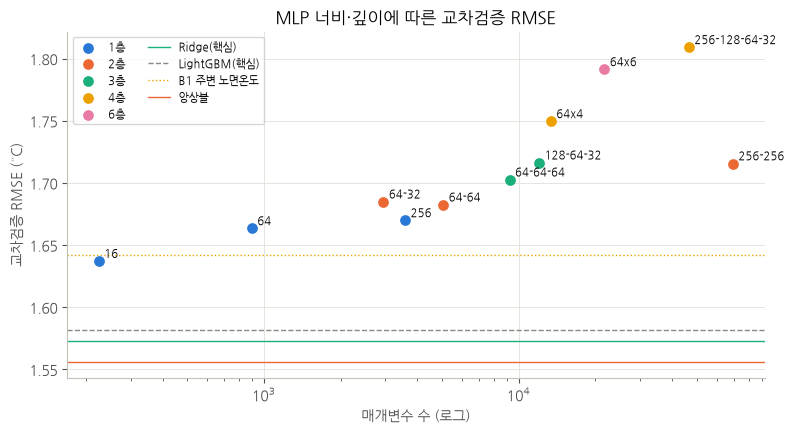

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plain = mlp_table[~mlp_table.index.str.contains(",")]
for depth, g in plain.groupby("층 수"):
    ax.scatter(g["매개변수 수"], g["CV RMSE"], s=45, label=f"{depth}층", zorder=3)
    for name, r in g.iterrows():
        ax.annotate(name.split(" ")[1], (r["매개변수 수"], r["CV RMSE"]), fontsize=8, xytext=(4, 3),
                    textcoords="offset points")
for name, color, style in [("Ridge(핵심)", "#1baf7a", "-"), ("LightGBM(핵심)", "#898781", "--"),
                           ("B1 주변 노면온도", "#eda100", ":"), ("앙상블", "#eb6834", "-")]:
    ax.axhline(cmp_table.loc[name, "CV RMSE"], color=color, linestyle=style, linewidth=1, label=name)
ax.set_xscale("log")
ax.set_xlabel("매개변수 수 (로그)")
ax.set_ylabel("교차검증 RMSE (°C)")
ax.set_title("MLP 너비·깊이에 따른 교차검증 RMSE")
ax.legend(fontsize=8, ncol=2)
plt.show()

- **작을수록 좋고 깊을수록 나쁘다.** 1층 16개(매개변수 225개)가 1.637°C로 가장 좋고, 같은 너비 64에서 층을 늘리면
  1층 1.663 → 2층 1.682 → 3층 1.703 → 4층 1.750 → 6층 1.791°C로 꾸준히 나빠진다. 너비를 키워도(256-256: 1.716) 마찬가지이다.
- 규제를 강하게 하거나(L2 1: 1.651) 시드 5개를 평균하면(1.647) 기본 구조(2층 64-32, 1.685)보다 나아진다. 규제를 약하게 하면(L2 1e-5: 1.674) 그보다 덜 나아진다.
  분산(과적합)을 줄이는 쪽이 도움이 되므로, MLP의 문제는 표현력 부족이 아니라 **지점 14곳에 대한 과적합**이다.
- 활성화 함수(tanh 1.672)나 목표 변수(B1 잔차 학습 1.641~1.737)를 바꿔도 크게 달라지지 않는다.
- 가장 좋은 MLP도 Ridge(1.573)·LightGBM(1.582)보다 나쁘다. 신경망의 이점(복잡한 비선형 관계)을 쓰려면
  지금보다 훨씬 많은 관측 지점이 필요하다.

### 3-3. 앙상블 실험

여러 모델의 예측을 합치는 방식을 비교한다. 후보는 3-1의 12개 방법(B1, B2, Ridge, Ridge 상호작용, 스플라인 GAM, kNN, RF, Extra Trees,
MLP, LightGBM, LightGBM 선형트리, XGBoost)이다.

| 방식 | 내용 |
|------|------|
| 고정 조합 | 2절의 앙상블(LightGBM + Ridge + B1), 12개 전체 평균, 12개 중앙값 |
| 조합 선택 | 1~4개 조합(793가지) 중 단순 평균 RMSE가 가장 낮은 조합 |
| 낮·밤 조합 선택 | 낮과 밤에 다른 조합을 쓴다 |
| 가중 평균 | 비음수·합 1 가중치를 RMSE 최소가 되도록 최적화 |
| 전진 선택 (Caruana et al. 2004) | 중복을 허용해 RMSE를 가장 줄이는 모델을 25번 더한다 |

조합·가중치를 같은 교차검증 결과로 고르면 점수가 부풀려진다. 그래서 **중첩 교차검증**을 쓴다:
7묶음마다 나머지 12개 지점의 교차검증 예측만으로 조합·가중치를 고르고, 그 묶음 지점에 적용한다.

In [9]:
POOL = ["B1 주변 노면온도", "B2 기온+노면편차", "Ridge(핵심)", "Ridge 상호작용(2차)", "스플라인 GAM", "kNN(k=200)",
        "Random Forest", "Extra Trees", "MLP(64-32)", "LightGBM(핵심)", "LightGBM 선형트리", "XGBoost"]
P = oof[POOL].to_numpy()
y_tr = train_all[TARGET].to_numpy()
valid = ~np.isnan(y_tr) & ~np.isnan(P).any(axis=1)
stn_pos = {s: i for i, s in enumerate(sorted(train_all["stn"].unique()))}
stn_code = train_all["stn"].map(stn_pos).to_numpy()
is_night = ((hr >= 19) | (hr <= 6)).to_numpy()


def station_mse(pred, mask=valid):
    e2 = np.where(mask, (pred - y_tr) ** 2, 0)
    return np.bincount(stn_code, e2, len(stn_pos)) / np.bincount(stn_code, mask.astype(float), len(stn_pos))


def mean_rmse(mse, idx=None):
    r = np.sqrt(mse)
    return r.mean() if idx is None else r[idx].mean()


subsets = [c for k in range(1, 5) for c in itertools.combinations(range(len(POOL)), k)]
mse_all = np.array([station_mse(P[:, list(c)].mean(axis=1)) for c in subsets])
mse_night = np.array([station_mse(P[:, list(c)].mean(axis=1), valid & is_night) for c in subsets])
mse_day = np.array([station_mse(P[:, list(c)].mean(axis=1), valid & ~is_night) for c in subsets])
order = np.argsort(np.sqrt(mse_all).mean(axis=1))
print("조합 크기별 최저 RMSE (같은 교차검증으로 고름, 낙관적):",
      {k: round(min(mean_rmse(mse_all[j]) for j, c in enumerate(subsets) if len(c) == k), 4) for k in range(1, 5)})
pd.DataFrame([{"조합": " + ".join(POOL[i] for i in subsets[j]), "CV RMSE (낙관적)": mean_rmse(mse_all[j])}
              for j in order[:8]]).round(4)

조합 크기별 최저 RMSE (같은 교차검증으로 고름, 낙관적): {1: np.float64(1.5614), 2: np.float64(1.5496), 3: np.float64(1.5486), 4: np.float64(1.5495)}


,조합,CV RMSE (낙관적)
0,Ridge(핵심) + LightGBM 선형트리 + XGBoost,1.5486
1,B1 주변 노면온도 + Ridge(핵심) + kNN(k=200) + LightGBM...,1.5495
2,Ridge(핵심) + LightGBM 선형트리,1.5496
3,Ridge(핵심) + MLP(64-32) + LightGBM 선형트리 + XGBoost,1.5504
4,B1 주변 노면온도 + Ridge(핵심) + kNN(k=200) + XGBoost,1.5506
5,Ridge(핵심) + XGBoost,1.5506
6,Ridge(핵심) + LightGBM(핵심) + LightGBM 선형트리,1.5508
7,Ridge(핵심) + Extra Trees + MLP(64-32) + XGBoost,1.5510


In [10]:
def pick_subset(idx, max_size=4):
    j = min((j for j, c in enumerate(subsets) if len(c) <= max_size), key=lambda j: mean_rmse(mse_all[j], idx))
    w = np.zeros(len(POOL))
    w[list(subsets[j])] = 1 / len(subsets[j])
    return w


def pick_daynight(idx):
    jn = min(range(len(subsets)), key=lambda j: mean_rmse(mse_night[j], idx))
    jd = min(range(len(subsets)), key=lambda j: mean_rmse(mse_day[j], idx))
    wn, wd = np.zeros(len(POOL)), np.zeros(len(POOL))
    wn[list(subsets[jn])], wd[list(subsets[jd])] = 1 / len(subsets[jn]), 1 / len(subsets[jd])
    return wn, wd


def pick_simplex(idx):
    m = valid & np.isin(stn_code, idx)
    Pm, ym, sc = P[m], y_tr[m], stn_code[m]
    n_s = np.bincount(sc, minlength=len(stn_pos))[idx]

    def loss(w):
        w = np.abs(w) / np.abs(w).sum()
        return np.sqrt(np.bincount(sc, (Pm @ w - ym) ** 2, len(stn_pos))[idx] / n_s).mean()
    r = minimize(loss, np.full(len(POOL), 1 / len(POOL)), method="Powell", options={"maxiter": 3000, "xtol": 1e-3})
    return np.abs(r.x) / np.abs(r.x).sum()


def pick_greedy(idx, steps=25):
    chosen, cur = [], np.zeros(len(y_tr))
    for t in range(steps):
        b = min(range(len(POOL)), key=lambda i: mean_rmse(station_mse((cur * t + P[:, i]) / (t + 1)), idx))
        chosen.append(b)
        cur = (cur * t + P[:, b]) / (t + 1)
    return np.bincount(chosen, minlength=len(POOL)) / steps


def apply_w(w, X, night_mask):
    if isinstance(w, tuple):
        return np.where(night_mask, X @ w[0], X @ w[1])
    return X @ w


PICKERS = {"조합 선택 (≤ 4개)": pick_subset, "조합 선택 (≤ 2개)": lambda idx: pick_subset(idx, 2),
           "낮·밤 조합 선택": pick_daynight, "가중 평균 (비음수, 합 1)": pick_simplex, "전진 선택 (Caruana)": pick_greedy}
ens_pred = {"2절 앙상블 (LightGBM + Ridge + B1)": oof["앙상블"].to_numpy(), "12개 평균": P.mean(axis=1),
            "12개 중앙값": np.median(P, axis=1)}
picked = {}
for name, pick in PICKERS.items():
    pred = np.full(len(y_tr), np.nan)
    for val_stns in folds:
        idx = np.array([stn_pos[s] for s in stn_pos if s not in val_stns])
        rows = train_all["stn"].isin(val_stns).to_numpy()
        pred[rows] = apply_w(pick(idx), P[rows], is_night[rows])
    ens_pred[name] = pred
    picked[name] = pick(np.arange(len(stn_pos)))  # 14개 지점 전체로 고른 구성 (검증 지점용)

Ph = ho_cmp[POOL].to_numpy()
ho_night = ((holdout["time"].dt.hour >= 19) | (holdout["time"].dt.hour <= 6)).to_numpy()
ho_ens = {"2절 앙상블 (LightGBM + Ridge + B1)": ho_cmp["앙상블"].to_numpy(), "12개 평균": Ph.mean(axis=1),
          "12개 중앙값": np.median(Ph, axis=1)}
ho_ens.update({name: apply_w(w, Ph, ho_night) for name, w in picked.items()})
ens_table = pd.DataFrame({
    "CV RMSE (중첩, 정직)": {k: mean_rmse(station_mse(v)) for k, v in ens_pred.items()},
    "밤(19~06시)": {k: mean_rmse(station_mse(v, valid & is_night)) for k, v in ens_pred.items()},
    "검증 지점 RMSE (참고)": per_station_rmse(holdout, pd.DataFrame(ho_ens, index=holdout.index)).mean(),
})
print("14개 지점으로 고른 구성:")
for name, w in picked.items():
    ws = w if not isinstance(w, tuple) else w[0]
    print(f"  {name}:", {POOL[i]: round(x, 2) for i, x in enumerate(ws) if x > 0.01}, "(밤)" if isinstance(w, tuple) else "")
ens_table.round(4)

14개 지점으로 고른 구성:
  조합 선택 (≤ 4개): {'Ridge(핵심)': np.float64(0.33), 'LightGBM 선형트리': np.float64(0.33), 'XGBoost': np.float64(0.33)} 
  조합 선택 (≤ 2개): {'Ridge(핵심)': np.float64(0.5), 'LightGBM 선형트리': np.float64(0.5)} 
  낮·밤 조합 선택: {'B1 주변 노면온도': np.float64(0.25), 'Ridge(핵심)': np.float64(0.25), 'MLP(64-32)': np.float64(0.25), 'XGBoost': np.float64(0.25)} (밤)
  가중 평균 (비음수, 합 1): {'B1 주변 노면온도': np.float64(0.1), 'Ridge(핵심)': np.float64(0.34), 'kNN(k=200)': np.float64(0.11), 'MLP(64-32)': np.float64(0.1), 'LightGBM 선형트리': np.float64(0.17), 'XGBoost': np.float64(0.19)} 
  전진 선택 (Caruana): {'B1 주변 노면온도': np.float64(0.08), 'Ridge(핵심)': np.float64(0.32), 'kNN(k=200)': np.float64(0.08), 'Extra Trees': np.float64(0.04), 'MLP(64-32)': np.float64(0.12), 'LightGBM 선형트리': np.float64(0.2), 'XGBoost': np.float64(0.16)} 


,"CV RMSE (중첩, 정직)",밤(19~06시),검증 지점 RMSE (참고)
2절 앙상블 (LightGBM + Ridge + B1),1.5558,1.0375,0.9373
12개 평균,1.5592,1.0411,0.9604
12개 중앙값,1.5481,1.0357,0.9625
조합 선택 (≤ 4개),1.6357,1.0958,0.9573
조합 선택 (≤ 2개),1.6336,1.0920,0.9602
낮·밤 조합 선택,1.6221,1.0517,0.9701
"가중 평균 (비음수, 합 1)",1.6214,1.0832,0.9619
전진 선택 (Caruana),1.6213,1.0818,0.9642


- 같은 교차검증으로 고른 최선 조합(Ridge + LightGBM 선형트리 + XGBoost, 1.549°C)은 낙관적이다. 조합을 고르는 과정까지 중첩 교차검증으로 평가하면
  1.636°C(4개 이하)로 2절 앙상블(1.556)보다 나빠진다. 묶음마다 고른 조합이 달라지기 때문이다.
- 가중치를 학습하는 방식(가중 평균 1.621, 전진 선택 1.621, 낮·밤 분리 1.622)도 중첩 점수가 **단순 평균보다 나쁘다.**
  지점 12곳으로 가중치 12개를 정하면 가중치가 학습 지점에 맞춰지기 때문이다.
- 고르는 과정이 없는 12개 중앙값(1.548)은 2절 앙상블보다 0.008°C 낮고, 12개 평균(1.559)은 거의 같다. 3-1의 상위 기법 간 차이와 같은 잡음 수준이다.
  같은 교차검증 예측으로 계산하면 B1 + Ridge 두 개의 평균이 1.574°C이고, 여기에 LightGBM을 더하면 1.556°C가 된다.
  **앙상블의 이득은 주변 관측 보간(B1)과 선형 모델(Ridge)의 평균에서 대부분 나오고, LightGBM이 0.02°C 정도를 더한다.**
- 검증 지점(참고)에서는 2절 앙상블(0.937)이 모든 대안(0.957~0.970)보다 낫다.
- **2절 앙상블을 유지한다.** 중앙값의 이득(0.008°C)은 잡음 수준이고, 12개 모델을 모두 학습해야 하며(느리고 학습마다 결과가 달라지는 kNN·MLP 포함),
  검증 지점에서는 오히려 나쁘다.

### 3-4. 잔차 구조: 무엇이 성능을 제한하는가

기법을 바꿔도 RMSE가 거의 그대로라면, 남은 오차가 모델로 배울 수 없는 성분일 가능성이 크다. Ridge 교차검증 잔차(추정 - 관측)의 분산을
나눠 본다.

- **지점 평균 편향**: 지점마다 늘 같은 방향으로 틀리는 양 (센서 위치·포장·주변 환경)
- **지점 x 시각 편향**: 지점마다 하루 중 같은 시각에 반복되는 오차 (예: 특정 지점이 매일 한낮에 덜 데워짐)
- 나머지: 날마다 달라지는 오차 (기상 보간 오차 등)

In [11]:
res = (oof["Ridge(핵심)"] - train_all[TARGET]).rename("r")
var_total = res.var()
var_station = res.groupby(train_all["stn"]).transform("mean").var()
var_station_hour = res.groupby([train_all["stn"], hr]).transform("mean").var()
pd.Series({"잔차 분산 (°C²)": var_total, "지점 평균 편향 비중": var_station / var_total,
           "지점 x 시각 편향 비중 (지점 평균 포함)": var_station_hour / var_total,
           "나머지 비중": 1 - var_station_hour / var_total}).round(3).to_frame("Ridge 교차검증 잔차")

,Ridge 교차검증 잔차
잔차 분산 (°C²),2.590
지점 평균 편향 비중,0.212
지점 x 시각 편향 비중 (지점 평균 포함),0.441
나머지 비중,0.559


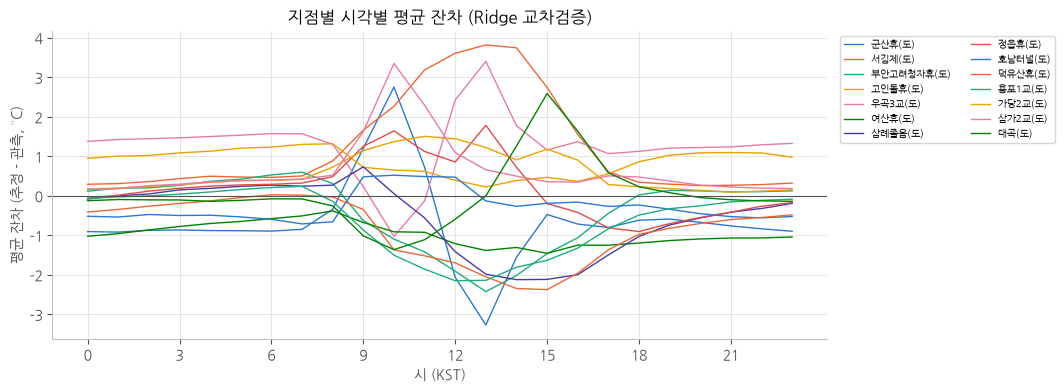

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
prof = res.groupby([train_all["stn"], hr]).mean().unstack(0)
for stn in prof.columns:
    ax.plot(prof.index, prof[stn], linewidth=1, label=stations.loc[stn, "name"])
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("시 (KST)")
ax.set_ylabel("평균 잔차 (추정 - 관측, °C)")
ax.set_title("지점별 시각별 평균 잔차 (Ridge 교차검증)")
ax.legend(ncol=2, fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

공간 보간(크리깅)으로 잔차를 줄일 수 있으려면 가까운 지점끼리 잔차가 **양의 상관**이어야 한다. 지점 쌍의 잔차 상관을 거리별로 본다.

In [13]:
pair_rows = []
for col, name in [("Ridge(핵심)", "Ridge"), ("B1 주변 노면온도", "B1")]:
    piv = (oof[col] - train_all[TARGET]).groupby([train_all["time"], train_all["stn"]]).first().unstack()
    corr = piv.corr()
    for a, b in itertools.combinations(piv.columns, 2):
        pair_rows.append({"잔차": name, "거리(km)": haversine_km(stations.loc[a], stations.loc[b]), "상관": corr.loc[a, b]})
pairs = pd.DataFrame(pair_rows)
pairs["거리대"] = pd.cut(pairs["거리(km)"], [0, 15, 30, 60, 200], labels=["15km 미만", "15~30km", "30~60km", "60km 이상"])
pairs.groupby(["거리대", "잔차"], observed=True)["상관"].agg(["mean", "count"]).unstack().round(2)

mean       count      
잔차         B1 Ridge    B1 Ridge
거리대                            
15km 미만 -0.58 -0.26     9     9
15~30km -0.08  0.01    16    16
30~60km  0.01  0.14    25    25
60km 이상 -0.00  0.06    41    41

- 잔차 분산의 21%는 지점 평균 편향, 44%는 지점 x 시각 편향(평균 편향 포함)이다. **오차의 절반 가까이가 "그 지점이 매일 같은 시각에
  같은 방향으로 틀리는" 체계적 성분이다.** 그림처럼 지점 간 편향은 한낮(11~16시)에 최대 ±3~4°C로 커진다. 일사로 데워지는 정도가 지점마다 다르기 때문이다.
- 이 성분은 센서 위치, 포장, 주변 차폐, 교량 구조 같은 지점 고유 특성에서 나온다. 입력 변수에 이를 설명하는 정보가 없고 학습 지점이 14곳뿐이라
  어떤 기법으로도 배울 수 없다. 3-1·3-2에서 기법을 바꿔도 RMSE가 거의 같은 이유이다.
- 15km 미만 지점 쌍의 잔차 상관은 **음수**이다 (Ridge -0.26, B1 -0.58). `nbr_rst`가 이미 이웃 관측값을 쓰기 때문이다.
  이웃 B가 늘 따뜻한 지점이면 A의 추정은 B 때문에 너무 높아지고, B의 추정(A의 관측을 씀)은 너무 낮아진다.
  그래서 잔차를 다시 공간 보간하면 같은 정보를 두 번 쓰는 셈이 되어 3-1의 "Ridge + 잔차 IDW"가 크게 나빠졌다.
  30km 이상 떨어지면 상관이 0에 가깝다 (B1 0.00, Ridge 0.06~0.14). 이웃 관측을 이미 쓴 모델의 잔차를 다시 공간 보간할 여지는 없다.
  3-6에서는 이웃 정보를 쓰지 않은 밑그림의 잔차에서 지점의 버릇(지문)을 뺀 뒤 크리깅해 이 문제를 피한다.

### 3-5. 지점 특성 변수 실험

3-4의 지점 고유 편향을 지점 특성으로 설명할 수 있는지 본다. 후보 지점 특성:

| 변수 | 의미 |
|------|------|
| `elev`, `tpi`, `relief` | 표고, 주변(1km) 대비 상대 높이, 기복량 |
| `shade_winter` | 동지 무렵 지형에 가려지는 직달 일사 비율 |
| `dist_river`, `log_bridge`, `log_tunnel` | 하천·교량·터널까지 거리 (교량·터널은 log10) |
| `bridge` | 교량 위(50m 이내) 여부 |
| `dz_nbr` | 주변 RWIS 3곳(IDW) 대비 높이 차. `nbr_rst`의 고정 감률 보정이 밤 역전층에서 틀릴 수 있는 정도 |
| `rest_area` | 센서가 휴게소·졸음쉼터 안에 있는지 (지점명 기준). 학습 지점 14곳 중 7곳 |

먼저 지점별 평균 잔차(편향)와 지점 특성의 순위 상관을 상황별로 본다 (지점 14곳).

In [14]:
from scipy.stats import spearmanr

site = stations.copy()
_g = gpd.GeoSeries(gpd.points_from_xy(site["lon"], site["lat"]), crs=4326).to_crs(5179)
_xy = np.c_[_g.x, _g.y]
_src = np.flatnonzero(~site["holdout"].to_numpy())
_d = cdist(_xy, _xy[_src])
for i, j in enumerate(_src):
    _d[j, i] = np.inf  # 학습 지점은 자기 자신 제외 (02-2의 주변 RWIS 변수와 같은 방식)
_near = np.argsort(_d, axis=1)[:, :3]
_w = 1 / np.maximum(np.take_along_axis(_d, _near, 1), 50) ** 2
site["dz_nbr"] = site["elev"] - (_w * site["elev"].to_numpy()[_src][_near]).sum(1) / _w.sum(1)
site["log_bridge"] = np.log10(site["dist_bridge"] + 10)
site["log_tunnel"] = np.log10(site["dist_tunnel"] + 10)
site["bridge"] = (site["dist_bridge"] < 50).astype(float)
site["rest_area"] = site["name"].str.contains("휴|졸음").astype(float)
SITE = ["elev", "tpi", "relief", "shade_winter", "dist_river", "log_bridge", "log_tunnel", "bridge", "dz_nbr", "rest_area"]

night_all = train_all["sun_elev"] <= 0
rci = night_all * (1 - train_all["cloud"].clip(0, 10) / 10) * (1 - train_all["ws"] / 5).clip(0, 1)  # 복사냉각 지수
SITUATIONS = {"전체": np.ones(len(train_all), bool), "밤": ((hr >= 19) | (hr <= 6)).to_numpy(),
              "맑고 고요한 밤": (rci > 0.5).to_numpy(), "한낮(11~14시)": ((hr >= 11) & (hr <= 14)).to_numpy()}
bias = pd.DataFrame({k: res[m].groupby(train_all.loc[m, "stn"]).mean() for k, m in SITUATIONS.items()})
site_corr = pd.DataFrame({k: {c: spearmanr(bias[k], site.loc[bias.index, c])[0] for c in SITE} for k in SITUATIONS})
site_corr.round(2)

,전체,밤,맑고 고요한 밤,한낮(11~14시)
elev,-0.27,-0.27,-0.23,-0.19
tpi,-0.01,0.16,0.22,-0.11
relief,-0.08,-0.15,-0.20,-0.04
shade_winter,-0.20,-0.36,-0.44,-0.08
dist_river,0.26,0.16,-0.07,0.16
log_bridge,-0.35,-0.33,-0.35,-0.41
log_tunnel,-0.20,0.01,0.11,-0.15
bridge,0.41,0.28,0.19,0.41
dz_nbr,-0.23,-0.42,-0.41,0.09
rest_area,-0.51,-0.37,-0.27,-0.48


상관이 있어 보이는 특성을 모델에 넣는 방법은 두 가지이다.

1. **행 단위**: 지점 특성을 그대로 입력 변수에 더한다 (10분 단위 40만 행).
2. **지점 단위 2단계 보정**: 기본 모델(Ridge)의 잔차로 지점 x 시각별 편향을 재고, 그 편향을 지점 특성으로 회귀(표본 12개 지점, 릿지 규제 λ)해
   새 지점의 편향을 예측해 뺀다. 학습 지점의 잔차는 **내부 교차검증**으로 구해 낙관적인 잔차를 쓰지 않는다.

In [15]:
STATIC_ROW = ["elev", "tpi", "relief", "shade_winter", "dist_river", "dist_bridge", "dist_tunnel"]
row_exp = {}
for name, make in [("Ridge", make_ridge), ("LightGBM", lambda: lgb.LGBMRegressor(**dict(
        LGB_PARAMS["LightGBM(핵심)"], n_estimators=best_iter["LightGBM(핵심)"])))]:
    pred = pd.Series(np.nan, index=train_all.index)
    for k, val_stns in enumerate(folds):
        f = fold_frame(k)
        rows = f["stn"].isin(val_stns)
        tr = f[~rows].dropna(subset=[TARGET])
        pred[rows] = make().fit(tr[CORE + STATIC_ROW], tr[TARGET]).predict(f.loc[rows, CORE + STATIC_ROW])
    base_name = "Ridge(핵심)" if name == "Ridge" else "LightGBM(핵심)"
    r = per_station_rmse(train_all, pd.DataFrame({"x": pred}))["x"]
    row_exp[f"{name} + 정적 변수 7개 (행 단위)"] = {"CV RMSE": r.mean(), "핵심 변수만": st_rmse[base_name].mean(),
                                               "나빠진 지점 수": int((r > st_rmse[base_name]).sum())}
pd.DataFrame(row_exp).T.round(3)

,CV RMSE,핵심 변수만,나빠진 지점 수
Ridge + 정적 변수 7개 (행 단위),1.882,1.573,8.0
LightGBM + 정적 변수 7개 (행 단위),1.780,1.582,9.0


In [16]:
# 바깥 묶음마다 학습 지점(12곳)의 내부 교차검증 잔차. 주변 RWIS 변수는 내부 묶음의 학습 지점(10곳)으로 다시 만든다
inner_res = {}
for k, val_stns in enumerate(folds):
    tr_mask = ~train_all["stn"].isin(val_stns)
    r = pd.Series(np.nan, index=train_all.index[tr_mask])
    for j, f in enumerate(folds):
        if j == k:
            continue
        fr = train_all.assign(**neighbor_features([s for s in TRAIN_STNS if s not in val_stns and s not in f]))
        ir = fr["stn"].isin(f)
        src = fr[tr_mask & ~ir].dropna(subset=[TARGET])
        r[fr.index[ir]] = make_ridge().fit(src[CORE], src[TARGET]).predict(fr.loc[ir, CORE]) - fr.loc[ir, TARGET]
    inner_res[k] = r

SOLAR_MAX = train_all["solar_eff"].max()


def regime_of(df, reg_name):
    """시각 24구분 또는 상황 4구분(맑고 고요한 밤 / 그 밖의 밤 / 햇빛 강한 낮 / 그 밖의 낮)."""
    if reg_name == "시각 24구분":
        return df["time"].dt.hour.to_numpy()
    night = df["sun_elev"] <= 0
    calm_clear = night * (1 - df["cloud"].clip(0, 10) / 10) * (1 - df["ws"] / 5).clip(0, 1) > 0.5
    return np.select([calm_clear.to_numpy(), night.to_numpy(), (df["solar_eff"] > 0.25 * SOLAR_MAX).to_numpy()],
                     [0, 1, 2], 3)


REGIMES = {name: (regime_of(train_all, name), n) for name, n in [("시각 24구분", 24), ("상황 4구분", 4)]}


def fit_bias(stn_ids, resid, regime, n_reg, desc, lam):
    """지점 x 상황 평균 잔차를 지점 특성 desc로 회귀(릿지 λ). 반환: 대상 지점 목록 -> (지점 x 상황) 편향 배열."""
    b = pd.DataFrame({"s": stn_ids, "g": regime, "r": resid}).dropna().groupby(["s", "g"])["r"].mean().unstack()
    b = b.reindex(columns=range(n_reg))
    X = site.loc[b.index, list(desc)].to_numpy(float)
    mu, sd = X.mean(0), X.std(0) + 1e-9
    coefs = []
    for gi in range(n_reg):
        yb = b[gi].to_numpy()
        ok = ~np.isnan(yb)
        A = np.c_[np.ones(ok.sum()), ((X - mu) / sd)[ok]]
        coefs.append(np.linalg.solve(A.T @ A + lam * np.diag([0.0] + [1.0] * len(desc)), A.T @ yb[ok]))
    coefs = np.array(coefs)
    return lambda tgt: coefs[:, 0][None, :] + ((site.loc[tgt, list(desc)].to_numpy(float) - mu) / sd) @ coefs[:, 1:].T


def corrected_oof(desc, reg_name, lam, base=oof["Ridge(핵심)"].to_numpy()):
    regime, n_reg = REGIMES[reg_name]
    pred = base.copy()
    for k, val_stns in enumerate(folds):
        rows = train_all["stn"].isin(val_stns).to_numpy()
        f = fit_bias(train_all.loc[~rows, "stn"].to_numpy(), inner_res[k].to_numpy(), regime[~rows], n_reg, desc, lam)
        B = f(list(val_stns))
        pos = {s: i for i, s in enumerate(val_stns)}
        pred[rows] -= B[train_all.loc[rows, "stn"].map(pos).to_numpy(), regime[rows]]
    return pred


CONFIGS = [((), r, 0.0) for r in REGIMES] + [((c,), r, lam) for c in SITE for r in REGIMES for lam in (0.0, 1.0, 5.0)]
two_rows = []
for desc, reg_name, lam in CONFIGS:
    r = per_station_rmse(train_all, pd.DataFrame({"x": corrected_oof(desc, reg_name, lam)}))["x"]
    two_rows.append({"지점 특성": "+".join(desc) or "(없음: 상황별 평균 편향)", "상황 구분": reg_name, "λ": lam,
                     "CV RMSE": r.mean(), "Ridge 대비": r.mean() - st_rmse["Ridge(핵심)"].mean(),
                     "개선 지점 수": int((r < st_rmse["Ridge(핵심)"]).sum())})
two_table = pd.DataFrame(two_rows).sort_values("CV RMSE")
two_table.head(10).round(4)

,지점 특성,상황 구분,λ,CV RMSE,Ridge 대비,개선 지점 수
58,rest_area,시각 24구분,5.0,1.5373,-0.0353,9
57,rest_area,시각 24구분,1.0,1.5479,-0.0247,9
61,rest_area,상황 4구분,5.0,1.5538,-0.0188,9
56,rest_area,시각 24구분,0.0,1.5538,-0.0188,9
60,rest_area,상황 4구분,1.0,1.5623,-0.0103,9
49,bridge,상황 4구분,5.0,1.5641,-0.0085,9
37,log_bridge,상황 4구분,5.0,1.5642,-0.0084,8
0,(없음: 상황별 평균 편향),시각 24구분,0.0,1.5645,-0.0081,9
46,bridge,시각 24구분,5.0,1.5656,-0.0070,8
34,log_bridge,시각 24구분,5.0,1.5665,-0.0061,9


위 표는 60여 가지 설정 가운데 가장 좋은 것을 같은 교차검증으로 고른 것이라 낙관적이다. 두 가지로 확인한다.

1. **중첩 선택**: 바깥 묶음마다 학습 지점 12곳의 내부 교차검증만으로 설정을 고르고 묶음 지점에 적용한다.
2. **검증 지점**: 14개 지점의 교차검증 잔차로 보정식을 학습해 2절 앙상블의 검증 지점 예측에 적용한다 (검증 지점 3곳은 모두 휴게소가 아니다).

In [17]:
nested_pred, nested_pick = oof["Ridge(핵심)"].to_numpy().copy(), []
for k, val_stns in enumerate(folds):
    rows = train_all["stn"].isin(val_stns).to_numpy()
    tr_stn, r_k = train_all.loc[~rows, "stn"].to_numpy(), inner_res[k].to_numpy()
    inner_folds = [f for j, f in enumerate(folds) if j != k]
    best, best_score = None, np.inf
    for desc, reg_name, lam in CONFIGS:
        regime, n_reg = REGIMES[reg_name]
        reg_k = regime[~rows]
        corr = r_k.copy()
        for f in inner_folds:
            ir = np.isin(tr_stn, f)
            B = fit_bias(tr_stn[~ir], r_k[~ir], reg_k[~ir], n_reg, desc, lam)(list(f))
            pos = {s: i for i, s in enumerate(f)}
            corr[ir] = r_k[ir] - B[[pos[s] for s in tr_stn[ir]], reg_k[ir]]
        score = np.sqrt(pd.Series(corr ** 2).groupby(tr_stn).mean()).mean()
        if score < best_score:
            best, best_score = (desc, reg_name, lam), score
    desc, reg_name, lam = best
    regime, n_reg = REGIMES[reg_name]
    B = fit_bias(tr_stn, r_k, regime[~rows], n_reg, desc, lam)(list(val_stns))
    pos = {s: i for i, s in enumerate(val_stns)}
    nested_pred[rows] -= B[train_all.loc[rows, "stn"].map(pos).to_numpy(), regime[rows]]
    nested_pick.append(f"{'+'.join(desc) or '없음'} / {reg_name} / λ={lam}")
r_nested = per_station_rmse(train_all, pd.DataFrame({"x": nested_pred}))["x"]
print(f"중첩 선택 CV RMSE {r_nested.mean():.4f} (Ridge {st_rmse['Ridge(핵심)'].mean():.4f}), "
      f"개선 지점 {int((r_nested < st_rmse['Ridge(핵심)']).sum())}/14")
print("묶음별 선택:", pd.Series(nested_pick).value_counts().to_dict())

중첩 선택 CV RMSE 1.6453 (Ridge 1.5726), 개선 지점 6/14
묶음별 선택: {'rest_area / 시각 24구분 / λ=5.0': 3, 'bridge / 시각 24구분 / λ=5.0': 2, 'rest_area / 시각 24구분 / λ=1.0': 1, 'tpi / 상황 4구분 / λ=1.0': 1}


In [18]:
best_desc, best_reg, best_lam = two_table.iloc[0][["지점 특성", "상황 구분", "λ"]]
best_desc = () if best_desc.startswith("(없음") else tuple(best_desc.split("+"))
reg_tr, n_best = REGIMES[best_reg]
reg_ho = regime_of(holdout, best_reg)
rows_ho = []
for base_name, base_oof, base_ho in [("Ridge(핵심)", oof["Ridge(핵심)"], ho_cmp["Ridge(핵심)"]),
                                     ("2절 앙상블", oof["앙상블"], ho_cmp["앙상블"])]:
    f = fit_bias(train_all["stn"].to_numpy(), (base_oof - train_all[TARGET]).to_numpy(), reg_tr, n_best, best_desc,
                 best_lam)
    B = f(list(config.HOLDOUT_STATIONS))
    pos = {s: i for i, s in enumerate(config.HOLDOUT_STATIONS)}
    corrected = base_ho.to_numpy() - B[holdout["stn"].map(pos).to_numpy(), reg_ho]
    before = per_station_rmse(holdout, pd.DataFrame({"x": base_ho}))["x"]
    after = per_station_rmse(holdout, pd.DataFrame({"x": corrected}, index=holdout.index))["x"]
    rows_ho.append({"기본 모델": base_name, "보정 전 검증 RMSE": before.mean(), "보정 후 검증 RMSE": after.mean(),
                    "보정 전 BIAS": (base_ho - holdout[TARGET]).mean(), "보정 후 BIAS": (corrected - holdout[TARGET]).mean()})
print(f"검증 지점에 적용한 설정: {'+'.join(best_desc) or '없음'} / {best_reg} / λ={best_lam}")
pd.DataFrame(rows_ho).set_index("기본 모델").round(3)

검증 지점에 적용한 설정: rest_area / 시각 24구분 / λ=5.0


,보정 전 검증 RMSE,보정 후 검증 RMSE,보정 전 BIAS,보정 후 BIAS
기본 모델,,,,
Ridge(핵심),0.994,1.155,-0.410,-0.720
2절 앙상블,0.937,1.086,-0.384,-0.636


- **진단**: 지점 편향과 상관이 가장 큰 특성은 다음과 같다.
  - 휴게소 여부 (전체 ρ = -0.51, 한낮 -0.48): 휴게소 센서는 모델보다 따뜻하게 관측된다.
  - 교량 거리 (한낮 -0.41): 교량에 가까울수록 한낮에 모델보다 차갑다. 01-7의 13-7과 같은 방향이다.
  - 주변 대비 높이 차 (밤 -0.42): 주변보다 높은 지점은 밤에 모델보다 따뜻하다. 역전층 때문이다.
  - 겨울 그늘 (맑고 고요한 밤 -0.44)

  다만 지점 14곳의 순위 상관은 |ρ| ≥ 0.54여야 5% 수준에서 유의하다.
- **행 단위**로 정적 변수를 넣으면 Ridge·LightGBM 모두 크게 나빠진다 (1.882, 1.780°C, 14곳 중 8~9곳 악화).
  40만 행 기준의 규제는 지점 수준에서는 사실상 없는 것과 같아, 정적 변수가 지점 식별자가 된다.
- **지점 단위 2단계 보정**은 겉보기에는 효과가 있다. 휴게소 여부로 시각별 편향을 보정하면 1.573 → 1.537°C로 줄어든다 (14곳 중 9곳 개선).
  학습 자료에서 휴게소 센서는 한낮(11~14시)에 모델보다 약 0.9°C 따뜻하게, 비휴게소 센서는 약 0.8°C 차갑게 관측된다. 휴게소 진입로·주차장 안의 센서는 본선보다 바람이 막히고
  차량 통행이 적어 더 데워질 가능성이 있다.
- 그러나 설정을 고르는 과정까지 포함한 **중첩 선택에서는 1.645°C로 오히려 나빠진다.** 묶음마다 고르는 특성이 바뀐다.
  **검증 지점에 적용해도 0.937 → 1.086°C로 나빠진다.** 검증 지점 3곳은 모두 휴게소가 아니다. 그런데 학습 자료의 비휴게소 지점
  (서김제·우곡3교처럼 한낮에 모델보다 차가운 곳)과 달리 오히려 모델보다 따뜻했다 (BIAS -0.38°C).
  비휴게소 지점끼리도 편차가 커서 "휴게소 여부" 하나로 설명되지 않는다.
- **결론: 지점 특성의 효과는 지점 14곳으로는 안정적으로 추정되지 않으므로 최종 모델에 넣지 않는다.**
  학습 지점의 절반이 휴게소 안 센서라는 점은 본선 구간 추정에 남아 있을 수 있는 편향 요인으로 05-1의 해석에 적는다.

### 3-6. RWIS 노면온도 보간 개선: 밑그림 + 지문 + 그날의 오차

2절의 B0(보간 기온을 노면온도로)와 B1(주변 RWIS 노면온도)의 차이가 보여 주듯, 노면온도의 빈칸은 공기 관측(AWS·ASOS)보다
주변 노면 관측(RWIS)이 훨씬 잘 채운다. AWS·ASOS는 공기를, RWIS는 아스팔트 표면을 재기 때문이다 (맑은 낮에는 노면이 기온보다 훨씬 뜨겁고
맑은 밤에는 더 차갑다, 01-7의 13-10). 그런데 지금까지 둘을 합치는 방식은 단순했다.

- B2: 보간 기온 + 주변 RWIS의 (노면온도 - 기온) 편차. 기준인 기온이 노면을 설명하기에 너무 약해서, 편차를 옮기면 그 지점에 맞지 않는
  일사·그늘 효과까지 함께 옮겨진다 (B1보다 나쁘다).
- Ridge·LightGBM: 주변 노면온도와 보간 기상을 나란히 입력할 뿐이다.
- 3-1의 Ridge + 잔차 IDW: Ridge가 이미 주변 노면온도를 입력으로 쓰고 있어 같은 이웃 정보를 두 번 썼다 (3-4).

선행연구는 노면온도를 날씨가 정하는 부분과 그 자리의 버릇으로 나눈다. 열지도(thermal mapping)는 노선을 따라 "늘 어디가 더 차갑고 따뜻한지"의
무늬(지문)가 밤마다 거의 같고 그 크기만 대기 안정도에 따라 달라진다고 본다 (Thornes 1991, Chapman et al. 2001에서 재인용, 01-1의 0-3).
기후 보조 보간(CAI, Willmott & Robeson 1995)은 관측값을 바로 보간하지 않고, 정밀한 밑그림 위에 밑그림과의 차이만 보간한다.
이를 따라 노면온도를 세 부분으로 나누고, 공간에서 퍼지는 방식이 다르므로 따로 옮긴다.

$$T_s(s, t) = \underbrace{T_b(s, t)}_{\text{밑그림}} + \underbrace{a(s, t)}_{\text{지문}} + \underbrace{e(s, t)}_{\text{그날의 오차}}$$

| 부분 | 뜻 | 만드는·옮기는 방법 |
|------|----|------------------|
| 밑그림 $T_b$ | "이 날씨라면 노면이 몇 도쯤일까" | AWS·ASOS 기상으로 대상 지점에서 직접 계산한다 (노면 에너지 수지를 단순화한 식, 3-6-1). 주변 RWIS 값은 넣지 않는다 |
| 지문 $a$ | 관측소 자리의 버릇 (휴게소 포장, 교량, 골짜기) | 원천마다 날씨에 따라 크기가 변하는 식으로 추정하고(3-6-2), 대상에는 거리에 따라 일부만 옮긴다 |
| 그날의 오차 $e$ | 밑그림이 못 잡은 그날의 차이 | 원천 사이의 공간 상관(준변동함수)을 재고 단순 크리깅으로 옮긴다 (3-6-3). 원천에서 멀어지면 0으로 줄어든다 |

모든 모수(밑그림 계수, 지문, 준변동함수)는 교차검증 묶음 안에서 학습 지점만으로 추정한다. 지문을 얼마나 옮길지 같은 설정은
**중첩 교차검증**으로 고른다 (바깥 묶음마다 나머지 6묶음의 내부 교차검증으로 고름, 3-3·3-5와 같음).

In [19]:
import rasterio
from scipy.optimize import least_squares
from scipy.signal import lfilter

STNS = stations.index.tolist()  # 17곳 (학습 14 + 검증 3)
TRAIN_IDX = np.array([STNS.index(s) for s in TRAIN_STNS])
HOLD_IDX = np.array([STNS.index(s) for s in config.HOLDOUT_STATIONS])
XY = STN_XY.loc[STNS].to_numpy()
ELEV = stations.loc[STNS, "elev"].to_numpy(float)
TIMES = pd.DatetimeIndex(sf.loc[sf["stn"] == STNS[0], "time"])
PERIOD = np.searchsorted([pd.Timestamp(s) for s, _ in config.PERIODS[1:]], TIMES, side="right")
SW = {c: sf.pivot(index="stn", columns="time", values=c).loc[STNS, TIMES].to_numpy(float)
      for c in ["rst", "ta", "td", "ws", "cloud", "sunshine", "sun_elev", "sunlit", "ta_obs"]}

# AWS: 산 정상(설천봉)·섬 AWS를 뺀다 (01-7의 14-1). 표고는 02-2의 3-1과 같은 방법(DEM 값 x 환산 계수, DEM 밖은 0m)
AWS_EXCLUDE = [314, 300, 700, 719, 756]
aws_st = pd.read_parquet(config.PROCESSED_DIR / "aws_stations.parquet")
aws_st = aws_st[~aws_st["stn"].isin(AWS_EXCLUDE)].reset_index(drop=True)
_g = gpd.GeoSeries(gpd.points_from_xy(aws_st["lon"], aws_st["lat"]), crs=4326).to_crs(5179)
AWS_XY = np.c_[_g.x, _g.y]
_aws = pd.read_parquet(config.PROCESSED_DIR / "aws_10min.parquet")
AWS = {v: _aws.pivot(index="stn", columns="time", values=v).reindex(index=aws_st["stn"], columns=TIMES).to_numpy(float)
       for v in ["ta", "td", "ws"]}
with rasterio.open(config.RAW_DIR / config.RAW_FILES["dem"]) as _src:
    _dem, _tf = _src.read(1).astype("float32"), _src.transform
_dem[_dem < -1000] = np.nan
_dem *= json.load(open(config.PROCESSED_DIR / "features.json", encoding="utf-8"))["dem_scale"]


def dem_elevation(xy):
    """점 표고(m): DEM 셀 값, nodata면 상하좌우 셀 평균, DEM 밖이면 0 (02-2의 3-1에서 반경 30m로 구한 것과 같음)."""
    out = []
    for x, y in xy:
        col, row = ~_tf * (x, y)
        row, col = int(row), int(col)
        if not (1 <= row < _dem.shape[0] - 1 and 1 <= col < _dem.shape[1] - 1):
            out.append(0.0)
            continue
        win = _dem[[row, row - 1, row + 1, row, row], [col, col, col, col - 1, col + 1]]
        out.append(win[0] if not np.isnan(win[0]) else (np.nanmean(win) if not np.isnan(win).all() else 0.0))
    return np.array(out, dtype=float)


AWS_ELEV = dem_elevation(AWS_XY)
print(f"AWS {len(aws_st)}곳 (제외 {AWS_EXCLUDE}), 표고 {AWS_ELEV.min():.0f}~{AWS_ELEV.max():.0f}m")

AWS 29곳 (제외 [314, 300, 700, 719, 756]), 표고 0~663m


#### 3-6-1. 밑그림: 노면 에너지 수지를 단순화한 식

노면온도는 흡수 일사, 하늘 장파, 노면 장파 방출, 현열, 잠열, 지중 열이 균형을 이루는 온도이다 (01-1의 0-2, 도로 예보 모델 METRo의
Crevier & Delage 2001도 같은 수지를 푼다). 노면온도가 기온과 크게 다르지 않다고 보고 장파 방출과 현열을 기온 근처에서 펴면 다음과 같다.

$$T_s - T_a \approx \frac{(1-\alpha)S_\downarrow + (L_\downarrow - \varepsilon\sigma T_a^4) - LE - G}{4\varepsilon\sigma T_a^3 + \rho c_p C_H u}$$

노면이 기온에서 벗어나는 정도는 "복사의 힘 ÷ 바람이 섞는 힘"이다. 맑고 바람 없는 밤에는 노면이 기온보다 많이 차가워지고, 바람이 불면 기온 쪽으로 붙는다.
각 항을 가진 자료로 만든다.

| 항 | 식 | 근거·자료 |
|----|----|------|
| 일사 $S_{eff}$ | $\max(\sin h, 0)\,(0.25 + 0.5\,SS \cdot sunlit)$ | Ångström–Prescott 형태, FAO-56 기본 계수 (Allen et al. 1998). $SS$: 보간 일조, $sunlit$: 지형 그늘 (02-2의 3-4) |
| 순 장파 $L_{net}$ | $-(1-N)(1-\varepsilon_{clr})\,\sigma T_a^4$, $\varepsilon_{clr} = 1.24\,(e/T_a)^{1/7}$ | 맑은 하늘 방출률 (Brutsaert 1975)에 구름 보정 $\varepsilon_{sky} = N + (1-N)\varepsilon_{clr}$ (Crawford & Duchon 1999)을 넣은 결과. $N$: 보간 운량, $e$: 이슬점의 수증기압 (hPa, K) |
| 열 저장 $M_S$, $M_L$ | 지난 몇 시간 $S_{eff}$, $L_{net}$의 지수 이동평균 (시간 상수 3시간) | 포장이 낮에 받은 열을 밤에 내놓는 효과 |

$$T_b = T_a + \frac{\beta_0(k) + \beta_1 S_{eff} + \beta_2 L_{net} + \beta_3 M_S + \beta_4 M_L}{1 + \beta_u u}$$

- $k$는 날씨 유형이다: 맑고 고요한 밤(복사냉각 지수 > 0.5, 3-5와 같은 정의), 그 밖의 밤, 햇빛 강한 낮(일사 지수 > 0.5), 그 밖의 낮.
- $\beta_u$는 0~1.5 격자에서 학습 자료의 제곱오차가 가장 작은 값을, 나머지 β는 최소제곱으로 구한다.
- **기온 $T_a$를 어떻게 보간하느냐**를 함께 비교한다. 02-2의 기온은 가까운 AWS 4곳의 IDW라서 AWS 주변의 국지 차이(골짜기, 해안)가 그대로 들어가고,
  밤 역전층 위에 있는 설천봉(01-7의 13-5)이 통영-대전선 지점 5곳(삼봉 포함)에 섞인다. 그래서 설천봉·섬 AWS를 뺀 AWS 29곳 전체로 더 매끄럽게
  보간한 기온도 만든다 (거리 제곱 반비례, 거리 반비례). 이슬점·풍속도 같은 방법으로 보간한다.

In [20]:
SIGMA_SB = 5.670374419e-8  # 슈테판-볼츠만 상수 (W/m²/K⁴)
A_S, B_S = 0.25, 0.50      # Ångström–Prescott 계수 (FAO-56 기본값)
TAU_H = 3.0                # 포장 열 저장의 시간 규모 (지수 이동평균, 시간)
S_MAX = (A_S + B_S) * np.sin(np.radians(np.nanmax(SW["sun_elev"])))  # 기간 중 가장 높은 해, 맑은 하늘의 S_eff
LAPSE_B = {"ta": 0.0065, "td": 0.002, "ws": 0.0}


def smooth_weather(tgt_xy, tgt_elev, t_idx=slice(None), power=1):
    """대상 지점의 기온·이슬점·풍속: 설천봉·섬을 뺀 AWS 전체의 역거리가중 평균 (고도 보정, 거리 power제곱 반비례).

    결측은 거의 없지만(모든 AWS가 비는 시각) 기간 안에서 앞뒤 값으로 채운다.
    """
    w = idw_weights(tgt_xy, AWS_XY, k=len(AWS_XY), power=power).astype(float)
    period = PERIOD[t_idx]
    out = {}
    for v, lapse in LAPSE_B.items():
        a = idw_apply(w, AWS[v][:, t_idx] + lapse * AWS_ELEV[:, None]).astype(float) - lapse * tgt_elev[:, None]
        for p in np.unique(period):
            idx = np.flatnonzero(period == p)
            a[:, idx] = pd.DataFrame(a[:, idx].T).ffill().bfill().to_numpy().T
        out[v] = a
    return out


def ema(a, step_h, period):
    """기간별 지수 이동평균 (시간 상수 TAU_H). 포장이 앞 몇 시간 동안 받은 열을 나타낸다."""
    alpha = 1 - np.exp(-step_h / TAU_H)
    out = np.empty_like(a)
    for p in np.unique(period):
        idx = np.flatnonzero(period == p)
        out[:, idx] = lfilter([alpha], [1, alpha - 1], a[:, idx], axis=1, zi=(1 - alpha) * a[:, idx[:1]])[0]
    return out


def surface_inputs(w, cloud, sunshine, sun_elev, sunlit, period, step_h):
    """밑그림 입력 (지점 x 시각). w: 기온·이슬점·풍속, 나머지는 02-2의 보간 운량·일조와 태양고도·지형 그늘."""
    ta, td, u = w["ta"], w["td"], w["ws"]
    n = np.clip(cloud / 10, 0, 1)
    s_eff = np.sin(np.radians(np.clip(sun_elev, 0, None))) * (A_S + B_S * sunshine * sunlit)  # 노면에 닿는 일사 (상대값)
    e = 6.112 * np.exp(17.62 * td / (243.12 + td))           # 수증기압 (hPa, 01-1과 같은 Magnus 상수)
    tak = ta + 273.15
    eps_clr = 1.24 * (e / tak) ** (1 / 7)                     # 맑은 하늘 방출률 (Brutsaert 1975)
    l_net = -(1 - n) * (1 - eps_clr) * SIGMA_SB * tak ** 4    # 순 장파 (W/m², Crawford & Duchon 1999의 하늘 방출률)
    night = sun_elev <= 0
    R = night * (1 - n) * np.clip(1 - u / 5, 0, 1)            # 복사냉각 지수 (3-5의 RCI와 같은 정의)
    S = s_eff / S_MAX                                         # 일사 지수 (0~1)
    regime = np.select([night & (R > 0.5), night, S > 0.5], [0, 1, 2], 3)
    return {"ta": ta, "u": u, "s_eff": s_eff, "l_net": l_net, "m_s": ema(s_eff, step_h, period),
            "m_l": ema(l_net, step_h, period), "R": R, "S": S, "regime": regime}


def take(inp, idx):
    return {k: v[idx] for k, v in inp.items()}


def expand(p, idx):
    """대상 idx의 값 (len(idx) x 시각)을 17곳 배열에 넣는다 (나머지 NaN)."""
    out = np.full((len(STNS), len(TIMES)), np.nan)
    out[idx] = p
    return out


_station_obs = lambda w: surface_inputs(w, SW["cloud"], SW["sunshine"], SW["sun_elev"], SW["sunlit"], PERIOD, 1 / 6)
TA_OPTIONS = {
    "02-2 기온 (가까운 4곳)": _station_obs({"ta": SW["ta"], "td": SW["td"], "ws": SW["ws"]}),
    "전체 AWS, 거리² 반비례": _station_obs(smooth_weather(XY, ELEV, power=2)),
    "전체 AWS, 거리 반비례": _station_obs(smooth_weather(XY, ELEV, power=1)),
}
REGIME_NAMES = ["맑고 고요한 밤", "그 밖의 밤", "햇빛 강한 낮", "그 밖의 낮"]
_reg = TA_OPTIONS["전체 AWS, 거리 반비례"]["regime"][TRAIN_IDX]
print("학습 지점 시간 중 날씨 유형 비율:", {REGIME_NAMES[k]: round(float((_reg == k).mean()), 3) for k in range(4)})

학습 지점 시간 중 날씨 유형 비율: {'맑고 고요한 밤': 0.225, '그 밖의 밤': 0.355, '햇빛 강한 낮': 0.149, '그 밖의 낮': 0.271}


#### 3-6-2. 지문: 원천 관측소의 버릇

원천 $j$의 총 잔차 $r_j(t) = T_{s,j}(t) - T_b(s_j, t)$를 날씨에 따라 크기가 변하는 지문으로 설명한다.

$$a_j(t) = a_j^0 + a_j^R\,R(t) + a_j^S\,S(t)$$

$R$은 복사냉각 지수(밤 x (1 - 운량) x 약한 바람), $S$는 일사 지수(0~1)이다. 지점마다 최소제곱으로 계수 3개를 구하고 지점 평균이 0이 되게 맞춘다
(지점 공통 부분은 밑그림이 갖는다). 지점 버릇이 밑그림 계수에 섞이지 않도록 밑그림과 지문을 번갈아 3번 추정한다.
아래는 학습 지점 14곳 전체로 추정한 밑그림 계수(매끄러운 기온, 거리 반비례)이다.

In [21]:
BASE_TERMS = ["s_eff", "l_net", "m_s", "m_l"]
WIND_GRID = (0.0, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5)  # 1/(1 + β_u·u)의 β_u 후보


def base_design(inp):
    reg = inp["regime"].ravel()
    return np.column_stack([(reg == k).astype(float) for k in range(4)] + [inp[c].ravel() for c in BASE_TERMS])


def base_map(inp, base):
    """밑그림 T_b = 기온 + [β0(유형) + β1·S_eff + β2·L_net + β3·M_S + β4·M_L] / (1 + β_u·풍속)."""
    x = base_design(inp) @ base["beta"] / (1 + base["beta_u"] * inp["u"].ravel())
    return inp["ta"] + x.reshape(inp["ta"].shape)


def fingerprint(coef, inp):
    """지문 a(t) = a0 + aR·R(t) + aS·S(t). coef: (지점 x 3)."""
    return coef[:, [0]] + coef[:, [1]] * inp["R"] + coef[:, [2]] * inp["S"]


def fit_base(inp, rst, n_iter=3):
    """원천 지점의 실측 노면온도로 밑그림 β와 지문 계수를 번갈아 추정한다. 주변 RWIS 값은 넣지 않는다.

    지문 계수는 지점 평균이 0이 되게 맞춰, 지점 공통 부분은 밑그림이 갖고 지점 고유 부분만 지문에 남긴다.
    """
    X, u = base_design(inp), inp["u"].ravel()
    coef = np.zeros((len(rst), 3))
    for _ in range(n_iter):
        y = (rst - inp["ta"] - fingerprint(coef, inp)).ravel()
        ok = ~np.isnan(y)
        best = None
        for bu in WIND_GRID:
            Xs = X[ok] / (1 + bu * u[ok])[:, None]
            beta = np.linalg.solve(Xs.T @ Xs, Xs.T @ y[ok])
            sse = ((Xs @ beta - y[ok]) ** 2).sum()
            if best is None or sse < best[0]:
                best = (sse, bu, beta)
        base = {"beta": best[2], "beta_u": best[1]}
        r = rst - base_map(inp, base)
        for j in range(len(rst)):
            m = ~np.isnan(r[j])
            A = np.c_[np.ones(m.sum()), inp["R"][j, m], inp["S"][j, m]]
            coef[j] = np.linalg.lstsq(A, r[j, m], rcond=None)[0]
        coef -= coef.mean(axis=0)
    base["coef"] = coef
    return base


full_base = fit_base(take(TA_OPTIONS["전체 AWS, 거리 반비례"], TRAIN_IDX), SW["rst"][TRAIN_IDX])
print(f"풍속 항 β_u = {full_base['beta_u']}")
pd.Series(full_base["beta"], index=[f"β0 {n}" for n in REGIME_NAMES] + ["β1 일사 S_eff", "β2 순장파 L_net (W/m²)",
                                                                       "β3 열저장 M_S", "β4 열저장 M_L (W/m²)"]).round(4)

풍속 항 β_u = 0.0


β0 맑고 고요한 밤            1.7239
β0 그 밖의 밤              0.9639
β0 햇빛 강한 낮             0.6237
β0 그 밖의 낮              0.3432
β1 일사 S_eff            7.3137
β2 순장파 L_net (W/m²)    0.0130
β3 열저장 M_S             8.4105
β4 열저장 M_L (W/m²)     -0.0063
dtype: float64

In [22]:
# 날씨 유형별 노면 - 기온: 밑그림과 실측 (학습 지점 14곳, 중앙값)
_inp = take(TA_OPTIONS["전체 AWS, 거리 반비례"], TRAIN_IDX)
_tb_gap, _obs_gap = base_map(_inp, full_base) - _inp["ta"], SW["rst"][TRAIN_IDX] - _inp["ta"]
pd.DataFrame({"밑그림 - 기온 (°C)": [np.nanmedian(_tb_gap[_inp["regime"] == k]) for k in range(4)],
              "실측 노면 - 기온 (°C)": [np.nanmedian(_obs_gap[_inp["regime"] == k]) for k in range(4)],
              "순 장파 L_net (W/m²)": [np.nanmedian(_inp["l_net"][_inp["regime"] == k]) for k in range(4)],
              "일사 S_eff": [np.nanmedian(_inp["s_eff"][_inp["regime"] == k]) for k in range(4)]},
             index=REGIME_NAMES).round(2)

,밑그림 - 기온 (°C),실측 노면 - 기온 (°C),순 장파 L_net (W/m²),일사 S_eff
맑고 고요한 밤,1.31,1.60,-92.00,0.00
그 밖의 밤,1.05,1.13,-15.01,0.00
햇빛 강한 낮,4.76,4.67,-92.31,0.37
그 밖의 낮,1.87,1.63,-29.51,0.11


In [23]:
fp_table = pd.DataFrame(full_base["coef"], columns=["a0 평소", "aR 맑고 고요한 밤", "aS 햇빛"],
                        index=pd.Index(TRAIN_STNS, name="stn"))
fp_table.insert(0, "지점명", stations.loc[TRAIN_STNS, "name"])
fp_table["표고(m)"] = ELEV[TRAIN_IDX]
fp_table["휴게소"] = site.loc[TRAIN_STNS, "rest_area"].astype(bool)
fp_table["교량(50m)"] = site.loc[TRAIN_STNS, "bridge"].astype(bool)
fp_table.round(2)

,지점명,a0 평소,aR 맑고 고요한 밤,aS 햇빛,표고(m),휴게소,교량(50m)
stn,,,,,,,
12103,군산휴(도),-0.18,-0.67,-0.46,22.18,True,False
12209,서김제(도),-0.17,-2.30,-6.65,20.16,False,True
12210,부안고려청자휴(도),0.13,-1.68,0.82,20.16,True,False
12211,고인돌휴(도),-0.29,-1.93,-1.22,60.49,True,False
12409,우곡3교(도),-1.01,-1.92,-1.51,20.16,False,False
23202,여산휴(도),0.32,0.86,1.12,61.50,True,False
23203,삼례졸음(도),-0.28,0.37,1.16,20.16,True,False
23204,정읍휴(도),-0.01,0.49,-1.92,20.16,True,False
23403,호남터널(도),-0.01,1.14,-0.63,110.90,False,False


- **밑그림은 날씨 유형별 노면-기온 차이를 잘 따라간다.** 햇빛 강한 낮에 노면은 기온보다 약 4.7°C 높고(밑그림 4.78°C),
  맑고 고요한 밤에도 기온보다 약 1.6°C 높다(밑그림 1.31°C). 밤에 노면이 기온보다 따뜻한 것은 지중 열 때문이다 (01-1의 0-2).
  B0(노면온도 = 보간 기온)가 크게 틀린 이유가 이 차이이다.
- 계수 가운데 일사(β1)와 열 저장(β3)이 가장 크다. 맑고 고요한 밤의 순 장파(중앙값 약 -92 W/m²)는 노면을 약 1.2°C 식힌다 (β2 x L_net).
- **풍속 항은 0으로 골라졌다 (β_u = 0).** 바람이 노면을 기온 쪽으로 끌어당기는 효과를 자료가 지지하지 않았다.
  보간한 AWS 풍속(지상 10m)이 노면 위 바람을 대표하지 못하고, 복사냉각 지수와 날씨 유형에 바람이 이미 들어가 있기 때문으로 보인다.
- **지문은 노선(지역)에 따라 갈린다.** 맑고 고요한 밤의 버릇 aR은 서해안선 5곳에서 모두 음수(-0.7 ~ -2.3°C, 밑그림보다 더 차가움)이고
  호남선·통영-대전선 9곳에서는 모두 양수(+0.4 ~ +1.6°C)이다. 이웃끼리 지문을 일부 공유할 근거이다.
- 햇빛 버릇 aS는 지점마다 크게 다르다. 서김제(-6.7)는 01-3의 4-2에서 본 것처럼 한낮 노면온도가 다른 지점보다 크게 낮고,
  용포1교(+4.1)·덕유산휴(+2.8)는 높다.
- **지문의 부호는 휴게소·교량 여부로 정리되지 않는다.** 휴게소 7곳의 aS는 4곳이 양수, 3곳이 음수이고, 교량 3곳의 aR은 1곳만 음수이다.
  "휴게소는 햇빛에 더 뜨겁고 교량은 맑은 밤에 더 차갑다"는 예상은 지점 단위로 확인되지 않는다 (3-5와 같은 결론).
- 평소 버릇 a0은 높은 곳일수록 크다 (덕유산휴 +1.0, 삼가2교·대곡 +0.5). 기온 보간의 0.65°C/100m가 노면에는 너무 크다는 뜻이며,
  3-6-4의 표고 추세에서 시험한다.

#### 3-6-3. 그날의 오차: 준변동함수와 단순 크리깅

지문을 뺀 그날의 오차 $e_j(t) = r_j(t) - a_j(t)$가 지점 사이에 얼마나 닮는지 지점 쌍의 반분산 $\gamma(d) = \tfrac12\,\overline{(e_i - e_j)^2}$로 잰다.
지수형 공분산 $C(d) = \sigma^2 e^{-d/L}$에 너깃 $\tau^2$를 더한 모형을 맞추고, 대상 지점의 오차를 단순 크리깅
$\hat e(s_0) = c(s_0)^\top (C + \tau^2 I)^{-1} e$로 구한다. 너깃을 대각선에 더하면 원천 값을 그대로 따라가지 않고
지점 사이에 공유되는 부분만 옮긴다 (측정오차가 있는 크리깅, Cressie 1993). 결측 원천은 그 시각의 계산에서 빠진다.

그날의 오차: 분산 2.68, 공간 상관 성분 σ² 1.62, 너깃 τ² 1.06, 상관 거리 L 237km


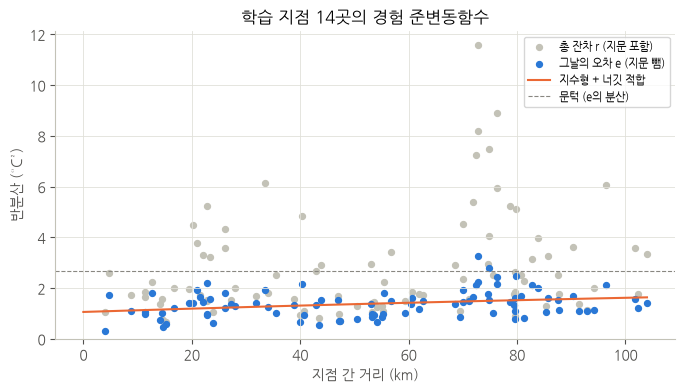

In [24]:
def pair_semivariance(e, xy):
    """원천 지점 쌍의 거리(km)와 반분산 ½·평균[(e_i - e_j)²]."""
    rows = []
    for i in range(len(e)):
        for j in range(i + 1, len(e)):
            ok = ~np.isnan(e[i]) & ~np.isnan(e[j])
            rows.append((np.hypot(*(xy[i] - xy[j])) / 1000, 0.5 * np.mean((e[i, ok] - e[j, ok]) ** 2)))
    return np.array(rows)


def fit_variogram(e, xy):
    """지수형 + 너깃: γ(d) = 문턱 - σ²·exp(-d/L). 문턱은 e²의 평균 (평균 0인 단순 크리깅)."""
    sill = np.nanmean(e ** 2)
    pv = pair_semivariance(e, xy)
    fit = least_squares(lambda p: sill - p[0] * np.exp(-pv[:, 0] / p[1]) - pv[:, 1], [0.5 * sill, 10.0],
                        bounds=([0, 0.5], [sill, 300]))
    return {"sill": sill, "sigma2": fit.x[0], "nugget": max(sill - fit.x[0], 1e-6), "L": fit.x[1], "pairs": pv}


def sk_weights(src_xy, tgt_xy, vg, use, exclude=None):
    """단순 크리깅 가중치 (대상 x 원천) = (C + τ²I)⁻¹c. use: 그 시각 쓸 수 있는 원천, exclude[i]: 대상 i에서 뺄 원천."""
    K = vg["sigma2"] * np.exp(-cdist(src_xy, src_xy) / 1000 / vg["L"]) + vg["nugget"] * np.eye(len(src_xy))
    c = vg["sigma2"] * np.exp(-cdist(tgt_xy, src_xy) / 1000 / vg["L"])
    W = np.zeros_like(c)
    for i in range(len(tgt_xy)):
        idx = np.flatnonzero(use & (np.arange(len(src_xy)) != (-1 if exclude is None else exclude[i])))
        W[i, idx] = np.linalg.solve(K[np.ix_(idx, idx)], c[i, idx])
    return W


def krige(E, src_xy, tgt_xy, vg, exclude=None):
    """원천의 그날의 오차 E (원천 x 시각)를 대상 지점으로 옮긴다. 결측 원천은 그 시각에서 빠진다."""
    avail = ~np.isnan(E)
    _, first, inv = np.unique(avail.T, axis=0, return_index=True, return_inverse=True)
    inv = inv.ravel()
    out, E0 = np.empty((len(tgt_xy), E.shape[1])), np.nan_to_num(E)
    for p, t0 in enumerate(first):
        cols = inv == p
        out[:, cols] = sk_weights(src_xy, tgt_xy, vg, avail[:, t0], exclude) @ E0[:, cols]
    return out


_inp = take(TA_OPTIONS["전체 AWS, 거리 반비례"], TRAIN_IDX)
full_r = SW["rst"][TRAIN_IDX] - base_map(_inp, full_base)
full_e = full_r - fingerprint(full_base["coef"], _inp)
full_vg = fit_variogram(full_e, XY[TRAIN_IDX])
pv_r = pair_semivariance(full_r, XY[TRAIN_IDX])
print(f"그날의 오차: 분산 {full_vg['sill']:.2f}, 공간 상관 성분 σ² {full_vg['sigma2']:.2f}, 너깃 τ² {full_vg['nugget']:.2f}, "
      f"상관 거리 L {full_vg['L']:.0f}km")
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(pv_r[:, 0], pv_r[:, 1], s=18, color="#c3c2b7", label="총 잔차 r (지문 포함)")
ax.scatter(full_vg["pairs"][:, 0], full_vg["pairs"][:, 1], s=18, color="#2a78d6", label="그날의 오차 e (지문 뺌)")
d = np.linspace(0, full_vg["pairs"][:, 0].max(), 200)
ax.plot(d, full_vg["sill"] - full_vg["sigma2"] * np.exp(-d / full_vg["L"]), color="#eb6834", label="지수형 + 너깃 적합")
ax.axhline(full_vg["sill"], color="#898781", linewidth=0.8, linestyle="--", label="문턱 (e의 분산)")
ax.set_xlabel("지점 간 거리 (km)")
ax.set_ylabel("반분산 (°C²)")
ax.set_ylim(0, None)
ax.set_title("학습 지점 14곳의 경험 준변동함수")
ax.legend(fontsize=8)
plt.show()

- 지문을 빼면 지점 쌍의 차이가 크게 준다. 모든 거리에서 그날의 오차(파랑)의 반분산이 총 잔차(회색)보다 작다.
- 그날의 오차의 분산 2.68°C² 가운데 1.62°C²(60%)가 공간 상관 성분, 1.06°C²(40%)가 너깃(지점 고유 잡음)이다.
- 상관 거리 L이 237km로 분석 지역(약 100km)보다 길다. 그날의 오차의 큰 부분이 **지역 전체가 함께 틀리는 성분**이라는 뜻이다
  (예: 그날 전 지역의 노면이 밑그림보다 따뜻함). 크리깅은 이 공통 성분을 모든 원천에서 모아 옮기고, 지점 고유 잡음(너깃)은 거른다.
- 15km 미만 쌍은 다른 쌍보다 반분산이 조금 작아 가까운 지점끼리 조금 더 닮지만, 이런 쌍이 9개뿐이라 짧은 거리 구조를 따로 맞추지는 않았다.

#### 3-6-4. 단계별 비교

한 단계씩 바꾸면서 무엇이 효과를 냈는지 본다. 지문을 옮기는 정도 φ와 거리 L은 φ ∈ {0, 0.25, 0.5, 0.75, 1}, L ∈ {2, 5, 10, 20, 40}km에서
중첩 교차검증으로 고른다 (φ = 0이면 지문을 옮기지 않는다).

| 단계 | 밑그림 | 지문 | 그날의 오차 | 확인하려는 것 |
|------|--------|------|-------------|---------------|
| B1 (2절) | 고도차 x 0.65°C/100m | 전부 복사 | IDW 3곳 | 기준 |
| B2 (2절) | 보간 기온 | 전부 복사 | IDW 3곳 | 기준 |
| R0 | 에너지 수지형 밑그림 | 없음 | 없음 | 밑그림만의 성능 |
| R1 | 밑그림 | 전부 복사 (총 잔차 IDW) | (지문과 함께) | 밑그림 개선 효과 (B2를 제대로 만든 형태) |
| R2 | 밑그림 | $g(d) = φ\,e^{-d/L}$만큼 (IDW) | IDW | 지문 덜어내기 효과 |
| R3 | 밑그림 | 크리깅 (너깃 비율로 φ) | 단순 크리깅 | 가중치 개선 효과 |
| R4 | R3 + 아래 과정 하나 | | | 추가 과정의 효과 |

R0~R3는 밑그림 기온을 02-2 방식과 매끄러운 보간으로 각각 만든다. R4의 세 과정은 다음과 같다.

- **표고 추세 (노면용 높이 보정)**: 기온 보간에 쓴 0.65°C/100m를 노면에 그대로 쓰지 않고, 지문 계수 3개를 표고에 회귀해 자료로 보정한다
  (지형 추세를 더한 회귀 크리깅). 3-5의 지점 특성 보정처럼 지점 14곳으로 정하는 정적 효과이다.
- **짧은 결측 채움**: 원천의 30분 이하 결측을 앞뒤 값으로 직선 보간한다. 긴 결측(01-2의 3-4에서 본 여산휴 27일 센서 고착 등)은 따로 채우지 않는다.
  단순 크리깅에서는 결측 원천을 "밑그림 + 지문 + 다른 원천으로 크리깅한 오차"로 채워 넣어도, 그 원천을 빼고 크리깅한 결과와 같기 때문이다.
- **RWIS 기온 원천**: 기본·거점 관측소 9곳이 고속도로 옆에서 직접 잰 기온을 AWS와 함께 기온 원천으로 쓴다 (원천인 지점은 자기 자신 제외).

In [25]:
FP_GRID = [(0.0, 0.0)] + [(p, l) for p in (0.25, 0.5, 0.75, 1.0) for l in (2.0, 5.0, 10.0, 20.0, 40.0)]


def fp_weights(src_xy, tgt_xy, phi, L, kind):
    """지문 옮김 가중치 (대상 x 원천).

    idw: 가까운 3곳 IDW 가중치 x g(d) = φ·exp(-d/L). krige: 상관 exp(-d/L), 너깃 비율 (1-φ)/φ인 단순 크리깅.
    원천이 하나뿐이면 두 방식 모두 φ·exp(-d/L)이 된다.
    """
    if phi == 0:
        return np.zeros((len(tgt_xy), len(src_xy)))
    if kind == "idw":
        w = idw_weights(tgt_xy, src_xy).astype(float)
        return w / w.sum(axis=1, keepdims=True) * phi * np.exp(-cdist(tgt_xy, src_xy) / 1000 / L)
    vg = {"sigma2": 1.0, "nugget": (1 - phi) / phi if phi < 1 else 1e-6, "L": L}
    return sk_weights(src_xy, tgt_xy, vg, np.ones(len(src_xy), bool))


def short_gap_fill(rst, limit=3):
    """30분(3칸) 이하 결측만 앞뒤 값으로 직선 보간한다 (기간별)."""
    out = rst.copy()
    for p in np.unique(PERIOD):
        idx = np.flatnonzero(PERIOD == p)
        out[:, idx] = pd.DataFrame(rst[:, idx].T).interpolate(limit=limit, limit_area="inside").to_numpy().T
    return out


def fit_parts(inp, rst, T, trend=False):
    """원천 T로 밑그림·지문·준변동함수를 추정한다. trend면 지문 계수를 표고에 회귀해 추세를 뗀다."""
    iT = take(inp, T)
    base = fit_base(iT, rst[T])
    r = rst[T] - base_map(iT, base)
    coef, g = base["coef"], None
    if trend:
        zc = ELEV[T] - ELEV[T].mean()
        g = (zc @ coef) / (zc @ zc)  # 표고 100m당이 아니라 1m당 계수 (3개)
        coef = coef - np.outer(zc, g)
    tr = fingerprint(np.outer(ELEV[T] - ELEV[T].mean(), g), iT) if trend else 0.0
    a = fingerprint(coef, iT)
    e = r - tr - a
    return {"base": base, "r": r, "a": a, "e": e, "vg": fit_variogram(e, XY[T]), "g": g, "zbar": ELEV[T].mean(), "T": T}


def predict_parts(inp, P, V, rungs, exclude=None):
    """성분 P(원천 P['T'])로 대상 V를 추정한다. 반환: {(단계, φ, L): (대상 x 시각) 예측}."""
    iV, T = take(inp, V), P["T"]
    tb = base_map(iV, P["base"])
    if P["g"] is not None:
        tb = tb + fingerprint(np.outer(ELEV[V] - P["zbar"], P["g"]), iV)
    xyT, xyV = XY[T], XY[V]
    out = {}
    if "R0" in rungs:
        out[("R0", 0.0, 0.0)] = tb
    if "R1" in rungs or "R2" in rungs:
        w3 = idw_weights(xyV, xyT)
        if "R1" in rungs:
            out[("R1", 0.0, 0.0)] = tb + idw_apply(w3, P["r"])
        if "R2" in rungs:
            e_idw = idw_apply(w3, P["e"])
            for phi, L in FP_GRID:
                out[("R2", phi, L)] = tb + fp_weights(xyT, xyV, phi, L, "idw") @ P["a"] + e_idw
    if "R3" in rungs:
        e_sk = krige(P["e"], xyT, xyV, P["vg"], exclude)
        for phi, L in FP_GRID:
            out[("R3", phi, L)] = tb + fp_weights(xyT, xyV, phi, L, "krige") @ P["a"] + e_sk
    return out

In [26]:
RWIS_TA = [i for i in TRAIN_IDX if np.isfinite(SW["ta_obs"][i]).mean() > 0.5]  # 기온 센서가 있는 기본·거점 관측소


def inputs_with_rwis_ta(T):
    """원천 T 가운데 기온 센서가 있는 RWIS의 실측 기온을 AWS와 함께 기온 원천으로 쓴다 (원천인 지점은 자기 자신 제외)."""
    src = [i for i in T if i in RWIS_TA]
    xy_s, z_s = np.r_[AWS_XY, XY[src]], np.r_[AWS_ELEV, ELEV[src]]
    excl = [len(AWS_XY) + src.index(i) if i in src else -1 for i in range(len(STNS))]
    w = idw_weights(XY, xy_s, k=len(xy_s), power=1, exclude=excl).astype(float)
    ta = idw_apply(w, np.r_[AWS["ta"], SW["ta_obs"][src]] + 0.0065 * z_s[:, None]).astype(float) - 0.0065 * ELEV[:, None]
    weather = dict(SMOOTH_P1, ta=pd.DataFrame(ta.T).ffill().bfill().to_numpy().T)
    return _station_obs(weather)


SMOOTH_P1 = smooth_weather(XY, ELEV, power=1)
B3_TA = "전체 AWS, 거리 반비례"
B3_CFG = ("R3", 0.0, 0.0)  # 앙상블 구성원 B3: 지문을 옮기지 않는다 (φ = 0)
LADDER = {  # 이름: (밑그림 기온, 단계, 표고 추세, 짧은 결측 채움, RWIS 기온 원천)
    "02-2 기온": ("02-2 기온 (가까운 4곳)", ["R0", "R1", "R2", "R3"], False, False, False),
    "평활 기온(거리²)": ("전체 AWS, 거리² 반비례", ["R0", "R1", "R3"], False, False, False),
    "평활 기온(거리)": (B3_TA, ["R0", "R1", "R2", "R3"], False, False, False),
    "+ 표고 추세": (B3_TA, ["R3"], True, False, False),
    "+ 짧은 결측 채움": (B3_TA, ["R3"], False, True, False),
    "+ RWIS 기온 원천": (B3_TA, ["R3"], False, False, True),
}
OOF_W = {m: np.full((len(STNS), len(TIMES)), np.nan) for m in ["LightGBM(핵심)", "Ridge(핵심)", "B1 주변 노면온도"]}
for m in OOF_W:
    OOF_W[m][TRAIN_IDX] = oof[m].to_numpy().reshape(len(TRAIN_STNS), len(TIMES))
FOLD_IDX = [np.array([STNS.index(s) for s in f]) for f in folds]
station_mse = lambda p, idx: dict(zip(idx, np.nanmean((p - SW["rst"][idx]) ** 2, axis=1)))
mean_rmse = lambda mse: float(np.mean(np.sqrt(list(mse.values()))))


def run_ladder(spec, keep_b3=False):
    """중첩 교차검증: 바깥 묶음마다 나머지 6묶음의 내부 교차검증으로 (φ, L)을 고른다."""
    ta_name, rungs, trend, fill, rwis = spec
    rst = short_gap_fill(SW["rst"]) if fill else SW["rst"]
    get_inp = inputs_with_rwis_ta if rwis else (lambda T: TA_OPTIONS[ta_name])
    res = {"pred": {r: np.full((len(STNS), len(TIMES)), np.nan) for r in rungs}, "pick": {r: [] for r in rungs},
           "outer_mse": {}, "ens_mse": {}, "b3_cv": np.full((len(STNS), len(TIMES)), np.nan), "b3_inner": []}
    for k, V in enumerate(FOLD_IDX):
        T = np.array([i for i in TRAIN_IDX if i not in V])
        inner_mse, b3_inner = {}, np.full((len(STNS), len(TIMES)), np.nan)
        for j, Vi in enumerate(FOLD_IDX):
            if j == k:
                continue
            Ti = np.array([i for i in T if i not in Vi])
            inp = get_inp(Ti)
            for cfg, p in predict_parts(inp, fit_parts(inp, rst, Ti, trend), Vi, rungs).items():
                inner_mse.setdefault(cfg, {}).update(station_mse(p, Vi))
                if keep_b3 and cfg == B3_CFG:
                    b3_inner[Vi] = p
        inp = get_inp(T)
        outer = predict_parts(inp, fit_parts(inp, rst, T, trend), V, rungs)
        for r in rungs:
            best = min((c for c in inner_mse if c[0] == r), key=lambda c: mean_rmse(inner_mse[c]))
            res["pick"][r].append(best[1:])
            res["pred"][r][V] = outer[best]
        for cfg, p in outer.items():
            res["outer_mse"].setdefault(cfg, {}).update(station_mse(p, V))
            if keep_b3 and cfg[0] == "R3":  # B3(φ, L)를 넣은 4구성원 앙상블
                ens = np.mean([p] + [OOF_W[m][V] for m in OOF_W], axis=0)
                res["ens_mse"].setdefault(cfg, {}).update(station_mse(ens, V))
        if keep_b3:
            res["b3_cv"][V] = outer[B3_CFG]
            res["b3_inner"].append(b3_inner)
    # 검증 지점(참고): 14곳 교차검증으로 고른 설정, 14곳 전체로 추정
    inp = get_inp(TRAIN_IDX)
    ho = predict_parts(inp, fit_parts(inp, rst, TRAIN_IDX, trend), HOLD_IDX, rungs)
    res["full_pick"] = {r: min((c for c in res["outer_mse"] if c[0] == r), key=lambda c: mean_rmse(res["outer_mse"][c]))
                        for r in rungs}
    res["ho"] = {r: expand(ho[res["full_pick"][r]], HOLD_IDX) for r in rungs}
    res["ho_all"] = {c: expand(p, HOLD_IDX) for c, p in ho.items()} if keep_b3 else None
    return res


_n_miss = int(np.isnan(SW["rst"][TRAIN_IDX]).sum())
_n_short = _n_miss - int(np.isnan(short_gap_fill(SW["rst"])[TRAIN_IDX]).sum())
print(f"학습 지점 노면온도 결측 {_n_miss:,}개 중 30분 이하 결측 {_n_short}개")
ladder = {}
for name, spec in LADDER.items():
    t0 = time.time()
    ladder[name] = run_ladder(spec, keep_b3=(name == "평활 기온(거리)"))
    print(f"{name}: {time.time() - t0:.0f}s, 묶음별 선택 (φ, L):",
          {r: pd.Series(map(str, p)).value_counts().to_dict() for r, p in ladder[name]["pick"].items() if r in ("R2", "R3")})

학습 지점 노면온도 결측 3,997개 중 30분 이하 결측 62개


02-2 기온: 26s, 묶음별 선택 (φ, L): {'R2': {'(0.75, 40.0)': 4, '(0.5, 40.0)': 2, '(0.5, 20.0)': 1}, 'R3': {'(0.5, 40.0)': 6, '(1.0, 20.0)': 1}}


평활 기온(거리²): 25s, 묶음별 선택 (φ, L): {'R3': {'(0.5, 40.0)': 5, '(0.75, 40.0)': 1, '(1.0, 20.0)': 1}}


평활 기온(거리): 26s, 묶음별 선택 (φ, L): {'R2': {'(0.75, 40.0)': 4, '(1.0, 40.0)': 1, '(0.5, 40.0)': 1, '(0.75, 20.0)': 1}, 'R3': {'(0.5, 40.0)': 4, '(0.75, 40.0)': 2, '(1.0, 20.0)': 1}}


+ 표고 추세: 26s, 묶음별 선택 (φ, L): {'R3': {'(0.0, 0.0)': 6, '(0.75, 10.0)': 1}}


+ 짧은 결측 채움: 26s, 묶음별 선택 (φ, L): {'R3': {'(0.5, 40.0)': 4, '(0.75, 40.0)': 2, '(1.0, 20.0)': 1}}


+ RWIS 기온 원천: 29s, 묶음별 선택 (φ, L): {'R3': {'(0.5, 40.0)': 5, '(0.75, 40.0)': 1, '(1.0, 20.0)': 1}}


In [27]:
RUNG_DESC = {"R0": "밑그림만", "R1": "밑그림 + 총 잔차 전부 복사(IDW)", "R2": "밑그림 + 지문 g(d)만큼(IDW) + 오차 IDW",
             "R3": "밑그림 + 지문 크리깅 + 오차 단순 크리깅"}
night_m, day_m, cold_m = (hr >= 19) | (hr <= 6), (hr >= 10) & (hr <= 15), train_all[TARGET] <= 2
ho_night = ((holdout["time"].dt.hour >= 19) | (holdout["time"].dt.hour <= 6)).to_numpy()


def to_rows(arr, df):
    """(17 x 시각) 배열을 df(stn, time 순서로 시각이 모두 있는 행)의 행 순서로 편다."""
    stns = df["stn"].unique()
    assert len(df) == len(stns) * len(TIMES)
    return np.concatenate([arr[STNS.index(s)] for s in stns])


def summarize(preds_tr, preds_ho):
    """교차검증 예측 (train_all 행)과 검증 지점 예측 (holdout 행) → 성적표."""
    P_tr, P_ho = pd.DataFrame(preds_tr, index=train_all.index), pd.DataFrame(preds_ho, index=holdout.index)
    st = per_station_rmse(train_all, P_tr)
    return pd.DataFrame({"CV RMSE": st.mean(), "밤(19~06시)": per_station_rmse(train_all, P_tr, night_m).mean(),
                         "낮(10~15시)": per_station_rmse(train_all, P_tr, day_m).mean(),
                         "노면 ≤ 2°C": per_station_rmse(train_all, P_tr, cold_m).mean(),
                         "검증 지점 RMSE (참고)": per_station_rmse(holdout, P_ho).mean()})


lad_tr = {"B1 주변 노면온도": oof["B1 주변 노면온도"].to_numpy(), "B2 기온+노면편차": oof["B2 기온+노면편차"].to_numpy()}
lad_ho = {"B1 주변 노면온도": holdout["nbr_rst"].to_numpy(), "B2 기온+노면편차": holdout["rst_phys"].to_numpy()}
pick_txt = {"B1 주변 노면온도": "", "B2 기온+노면편차": ""}
for name, lres in ladder.items():
    for r in lres["pred"]:
        label = f"{r} {RUNG_DESC[r]} [{name}]" if not name.startswith("+") else f"R4 R3{name} [평활 기온(거리)]"
        lad_tr[label], lad_ho[label] = to_rows(lres["pred"][r], train_all), to_rows(lres["ho"][r], holdout)
        pick_txt[label] = ", ".join(f"{k}×{v}" for k, v in pd.Series([f"φ{p:g}/L{l:g}" for p, l in lres["pick"][r]])
                                    .value_counts().items()) if r in ("R2", "R3") else ""
ladder_table = summarize(lad_tr, lad_ho)
ladder_table["묶음별 선택 (φ/L km)"] = pd.Series(pick_txt)
_r3, _r4 = "R3 밑그림 + 지문 크리깅 + 오차 단순 크리깅 [평활 기온(거리)]", "R4 R3+ 표고 추세 [평활 기온(거리)]"
_bias = pd.DataFrame({k: pd.Series(lad_ho[k] - holdout[TARGET].to_numpy()).groupby(holdout["stn"].to_numpy()).mean()
                      for k in [_r3, _r4]}).rename(index=stations["name"]).T
_bias.index = ["R3 (평활 기온)", "R4 표고 추세"]
print("검증 지점 BIAS (추정 - 관측, °C, 참고):")
print(_bias.round(2).to_string())
ladder_table.round(3)

검증 지점 BIAS (추정 - 관측, °C, 참고):
            부곡교(도)  해전(도)  삼봉(도)
R3 (평활 기온)   -0.84  -0.86   0.12
R4 표고 추세     -1.04  -1.28   0.62


,CV RMSE,밤(19~06시),낮(10~15시),노면 ≤ 2°C,검증 지점 RMSE (참고),묶음별 선택 (φ/L km)
B1 주변 노면온도,1.642,1.091,2.459,1.307,0.987,
B2 기온+노면편차,1.824,1.356,2.536,1.524,0.952,
R0 밑그림만 [02-2 기온],2.085,1.662,2.824,1.740,1.648,
R1 밑그림 + 총 잔차 전부 복사(IDW) [02-2 기온],1.813,1.344,2.522,1.508,0.959,
R2 밑그림 + 지문 g(d)만큼(IDW) + 오차 IDW [02-2 기온],1.745,1.320,2.429,1.484,0.979,"φ0.75/L40×4, φ0.5/L40×2, φ0.5/L20×1"
R3 밑그림 + 지문 크리깅 + 오차 단순 크리깅 [02-2 기온],1.627,1.276,2.185,1.400,1.165,"φ0.5/L40×6, φ1/L20×1"
R0 밑그림만 [평활 기온(거리²)],2.067,1.661,2.780,1.724,1.598,
R1 밑그림 + 총 잔차 전부 복사(IDW) [평활 기온(거리²)],1.724,1.238,2.460,1.425,0.977,
R3 밑그림 + 지문 크리깅 + 오차 단순 크리깅 [평활 기온(거리²)],1.545,1.164,2.137,1.312,1.121,"φ0.5/L40×5, φ0.75/L40×1, φ1/L20×1"
R0 밑그림만 [평활 기온(거리)],2.001,1.514,2.800,1.622,1.564,


- **밑그림만으로도(R0) 보간 기온(B0)보다 1°C 이상 좋다** (2.00~2.09°C, 2절의 B0는 3.12°C). 일사·장파·열 저장 항이 노면과 공기의 차이를 설명한다.
  그래도 주변 RWIS 관측을 쓰는 B1(1.642)보다는 나쁘다. 날씨만으로는 지점마다의 버릇과 그날의 차이를 알 수 없기 때문이다.
- **R1(밑그림 + 총 잔차 복사)은 B2를 제대로 만든 형태이다.** 02-2 기온으로는 B2와 거의 같다 (1.813 vs 1.824).
- **밑그림 기온을 매끄럽게 할수록 모든 단계가 좋아진다** (R3: 02-2 기온 1.627 → 거리² 1.545 → 거리 1.503). 가까운 AWS 4곳의 국지 차이(골짜기·해안)는
  공기에는 맞지만 노면에는 잡음이고, 이 잡음이 밑그림을 거쳐 노면 추정으로 옮겨지기 때문이다.
- 지문을 덜어내고(R2) 크리깅으로 옮기면(R3) 더 좋아진다. 매끄러운 기온에서 R1 1.657 → R2 1.607 → R3 1.503으로,
  **R3는 B1보다 0.14°C 낮다.** 중첩 교차검증은 대부분 φ = 0.5, L = 40km를 골랐다. 지문의 절반 정도를 수십 km 규모로 공유하는 것이 교차검증 지점에 맞았다.
- **검증 지점(참고)에서는 반대이다.** R3는 1.12~1.17°C로 B1(0.987)보다 나쁘다. 검증 지점 3곳은 모두 4km 안에 이웃 관측소가 있어(01-7의 14-1)
  이웃의 지문을 그대로 옮기는 B1이 유리하고, L = 40km는 먼 원천의 지문까지 섞는다. 반면 교차검증 지점은 14곳 중 10곳이 가장 가까운 원천과
  5km 넘게 떨어져 있어(3-6-6) 이렇게 가까운 조건을 거의 시험하지 못한다. 그래서 R3를 단독으로 쓰지 않고, 이웃의 지문은 B1에 맡기는 앙상블 구성원으로 쓴다 (3-6-5).
- R4의 세 과정은 넣지 않는다.
  - **표고 추세**는 교차검증을 가장 많이 낮추지만(1.464) 검증 지점에서 크게 나빠진다(1.392). 위 BIAS처럼 평지인 부곡교·해전은 더 차갑게,
    산지인 삼봉은 더 따뜻하게 추정해 세 곳 모두 틀리는 방향으로 움직인다. 지문 계수와 표고의 관계가 노선 차이(서해안선 평지의 aR 음수,
    산지의 양수)와 겹쳐 있기 때문이다. 3-5의 지점 특성 보정처럼, 지점 14곳으로 정한 정적 효과는 새 지점에 안정적으로 옮겨지지 않는다.
  - **짧은 결측 채움**은 결과가 같다. 학습 지점 결측 3,997개 가운데 30분 이하는 62개뿐이다.
  - **RWIS 기온 원천**은 교차검증이 거의 같고(1.500 vs 1.503) 검증 지점은 나빠진다(1.155 vs 1.123). 기온 센서가 있는 9곳 가운데 7곳이 휴게소라
    휴게소 주변 기온의 국지 차이가 들어간다 (02-2의 3-5에서 여산휴의 보간 기온 편차 -1.3°C).

#### 3-6-5. 앙상블 구성원 B3

단계별 비교에서 가장 좋은 단독 방법이라도, 2절 앙상블에 어떻게 넣느냐는 따로 정해야 한다. 앙상블에는 이미 B1이 있고, B1은 이웃의 지문까지 전부 옮긴다.
그래서 앙상블에 넣는 구성원 **B3는 매끄러운 기온의 R3에서 지문을 옮기지 않는 형태(φ = 0)**로 정한다: 밑그림 + 그날의 오차 크리깅.
같은 이웃 정보를 두 번 쓰지 않기 위해서이고(3-4), B1과 B3를 평균하면 지문의 절반을 옮기는 셈이 된다. φ를 바꾼 결과는 아래 민감도 표에서 따로 본다.

비교하는 쓰임새는 세 가지이다.

1. 2절 앙상블(LightGBM + Ridge + B1)에 B3를 더한다 (4구성원 단순 평균).
2. 2절 앙상블에서 B1 대신 B3를 쓴다.
3. B3를 주변 RWIS 변수(`nbr_rst`, `rst_phys`) 대신 Ridge·LightGBM의 입력으로 쓴다. 학습 행의 B3는 내부 교차검증 값(그 지점 관측을 쓰지 않은 값)이다.

In [28]:
B3_NAME = "B3 밑그림+크리깅"
lad = ladder["평활 기온(거리)"]
B3_CV, B3_HO = lad["b3_cv"], lad["ho_all"][B3_CFG]
oof[B3_NAME], ho_cmp[B3_NAME] = to_rows(B3_CV, train_all), to_rows(B3_HO, holdout)
ENS_BASE = ["LightGBM(핵심)", "Ridge(핵심)", "B1 주변 노면온도"]
FINAL_ENSEMBLE = ENS_BASE + [B3_NAME]
for df_, name, members in [(oof, "앙상블+B3", FINAL_ENSEMBLE), (ho_cmp, "앙상블+B3", FINAL_ENSEMBLE),
                           (oof, "앙상블(B1 대신 B3)", ["LightGBM(핵심)", "Ridge(핵심)", B3_NAME]),
                           (ho_cmp, "앙상블(B1 대신 B3)", ["LightGBM(핵심)", "Ridge(핵심)", B3_NAME])]:
    df_[name] = df_[members].mean(axis=1)

# B3를 주변 RWIS 변수(nbr_rst, rst_phys) 대신 Ridge·LightGBM 입력으로: 학습 행은 내부 교차검증 B3, 검증 행은 바깥 B3
CORE_B3 = [B3_NAME] + [c for c in CORE if c not in ("nbr_rst", "rst_phys")]
lgb_b3 = dict(LGB_PARAMS["LightGBM(핵심)"], n_estimators=best_iter["LightGBM(핵심)"])
for name in ["Ridge(B3 입력)", "LightGBM(B3 입력)"]:
    oof[name] = np.nan
for k, val_stns in enumerate(folds):
    f = fold_frame(k)
    b3 = lad["b3_inner"][k].copy()
    b3[FOLD_IDX[k]] = B3_CV[FOLD_IDX[k]]
    f[B3_NAME] = to_rows(b3, train_all)
    rows = f["stn"].isin(val_stns)
    tr = f[~rows].dropna(subset=[TARGET])
    oof.loc[rows, "Ridge(B3 입력)"] = make_ridge().fit(tr[CORE_B3], tr[TARGET]).predict(f.loc[rows, CORE_B3])
    oof.loc[rows, "LightGBM(B3 입력)"] = lgb.LGBMRegressor(**lgb_b3).fit(tr[CORE_B3], tr[TARGET]).predict(f.loc[rows, CORE_B3])
tr_b3 = train_all.assign(**{B3_NAME: oof[B3_NAME]}).dropna(subset=[TARGET])
ho_b3 = holdout.assign(**{B3_NAME: ho_cmp[B3_NAME]})
ho_cmp["Ridge(B3 입력)"] = make_ridge().fit(tr_b3[CORE_B3], tr_b3[TARGET]).predict(ho_b3[CORE_B3])
ho_cmp["LightGBM(B3 입력)"] = lgb.LGBMRegressor(**lgb_b3).fit(tr_b3[CORE_B3], tr_b3[TARGET]).predict(ho_b3[CORE_B3])

ENS_ROWS = ["B1 주변 노면온도", "Ridge(핵심)", "LightGBM(핵심)", "앙상블", B3_NAME, "Ridge(B3 입력)", "LightGBM(B3 입력)",
            "앙상블(B1 대신 B3)", "앙상블+B3"]
ens_b3_table = summarize({m: oof[m].to_numpy() for m in ENS_ROWS}, {m: ho_cmp[m].to_numpy() for m in ENS_ROWS})
_st = per_station_rmse(train_all, oof[ENS_ROWS])
_d = _st.sub(_st["앙상블"], axis=0)
ens_b3_table.insert(4, "앙상블(03-1) 대비 차이", _d.mean())
ens_b3_table.insert(5, "표준오차", _d.std() / np.sqrt(len(_d)))
ens_b3_table.insert(6, "나아진 지점 수", (_d < 0).sum())
ens_b3_table.round(3)

,CV RMSE,밤(19~06시),낮(10~15시),노면 ≤ 2°C,앙상블(03-1) 대비 차이,표준오차,나아진 지점 수,검증 지점 RMSE (참고)
B1 주변 노면온도,1.642,1.091,2.459,1.307,0.086,0.037,4,0.987
Ridge(핵심),1.573,1.069,2.319,1.259,0.017,0.019,7,0.994
LightGBM(핵심),1.582,1.072,2.337,1.312,0.026,0.021,6,0.999
앙상블,1.556,1.038,2.313,1.257,0.000,0.000,0,0.937
B3 밑그림+크리깅,1.590,1.203,2.218,1.359,0.034,0.091,8,1.083
Ridge(B3 입력),1.562,1.151,2.210,1.323,0.006,0.068,6,1.207
LightGBM(B3 입력),1.592,1.190,2.249,1.349,0.037,0.072,6,1.194
앙상블(B1 대신 B3),1.507,1.039,2.208,1.235,-0.048,0.042,10,0.924
앙상블+B3,1.513,1.028,2.232,1.231,-0.043,0.026,10,0.892


- **2절 앙상블에 B3를 더하면 교차검증 RMSE가 1.556 → 1.513°C로 준다** (차이 -0.043 ± 0.026°C, 14곳 중 10곳 개선).
  검증 지점(참고)도 0.937 → 0.892°C로 준다. 밤(1.038 → 1.028), 낮(2.313 → 2.232), 노면 2°C 이하(1.257 → 1.231)에서 모두 나아진다.
- B3 단독(1.590)은 Ridge(1.573)·LightGBM(1.582)과 비슷한 수준이지만, 주변 노면온도를 직접 쓰지 않아 오차가 생기는 방식이 다르다.
  그래서 앙상블에 더했을 때 이득이 크다.
- B1 대신 B3를 쓰는 구성(1.507)은 교차검증이 조금 더 낮지만, 두 구성의 차이(0.006°C)는 표준오차보다 훨씬 작아 교차검증으로 가릴 수 없다.
  B1을 빼면 가까운 이웃의 지문을 옮기는 구성원이 없어진다. 구간 233개의 56%는 가장 가까운 학습 관측소가 5km 안에 있는데(3-6-7),
  교차검증 지점은 14곳 중 4곳만 그런 조건이라 이 상황을 충분히 시험하지 못한다(3-6-6). 그래서 B1을 남기고 B3를 더한다.
  검증 지점(참고)에서도 이 구성이 낫다 (0.892 vs 0.924).
- B3를 주변 RWIS 변수 대신 Ridge·LightGBM의 입력으로 쓰면 교차검증은 비슷하지만(1.562, 1.592) 검증 지점에서 크게 나빠진다(1.207, 1.194).
  가까운 이웃의 노면온도(`nbr_rst`)가 입력에서 빠지기 때문이다. 입력으로 바꾸지 않고 구성원으로 더한다.

In [29]:
_b3 = {c: mean_rmse(v) for c, v in lad["outer_mse"].items() if c[0] == "R3"}
_ho = {}
for c, p in lad["ho_all"].items():
    if c[0] == "R3":
        _ens = (to_rows(p, holdout) + ho_cmp[ENS_BASE].sum(axis=1).to_numpy()) / 4
        _ho[c] = per_station_rmse(holdout, pd.DataFrame({"x": _ens}, index=holdout.index))["x"].mean()
_ens = {c: mean_rmse(v) for c, v in lad["ens_mse"].items()}
phi_table = pd.DataFrame({"B3 단독 CV": _b3, "앙상블+B3 CV": _ens, "앙상블+B3 검증 지점 (참고)": _ho})
phi_table.index = [f"φ={p:g}" + ("" if p == 0 else f", L={l:g}km") for _, p, l in phi_table.index]
phi_table.round(3).T

,φ=0,"φ=0.25, L=2km","φ=0.25, L=5km","φ=0.25, L=10km","φ=0.25, L=20km","φ=0.25, L=40km","φ=0.5, L=2km","φ=0.5, L=5km","φ=0.5, L=10km","φ=0.5, L=20km","φ=0.5, L=40km","φ=0.75, L=2km","φ=0.75, L=5km","φ=0.75, L=10km","φ=0.75, L=20km","φ=0.75, L=40km","φ=1, L=2km","φ=1, L=5km","φ=1, L=10km","φ=1, L=20km","φ=1, L=40km"
B3 단독 CV,1.590,1.588,1.571,1.541,1.514,1.502,1.585,1.556,1.514,1.488,1.479,1.584,1.545,1.502,1.488,1.485,1.582,1.538,1.502,1.510,1.530
앙상블+B3 CV,1.513,1.514,1.514,1.513,1.512,1.511,1.514,1.515,1.515,1.514,1.513,1.515,1.516,1.517,1.518,1.518,1.515,1.518,1.521,1.525,1.529
앙상블+B3 검증 지점 (참고),0.892,0.892,0.892,0.900,0.913,0.920,0.891,0.893,0.905,0.922,0.932,0.892,0.895,0.908,0.922,0.933,0.892,0.897,0.908,0.915,0.917


- B3 단독으로는 지문을 옮길수록 좋아지지만(φ = 0.5, L = 40km에서 1.479°C), **앙상블+B3의 교차검증은 φ·L에 거의 관계없다** (1.511~1.529°C).
  B1이 이미 이웃의 지문을 옮기고 있어서, B3에서 지문을 또 옮겨도 앙상블에 더해지는 정보가 거의 없다.
- 검증 지점(참고)에서는 지문을 멀리 옮길수록(L이 클수록) 나빠진다 (φ = 0: 0.892, φ = 0.5·L = 40km: 0.932).
- 그래서 B3는 φ = 0으로 둔다. 교차검증에서 잃는 것이 없고(1.513, 최저 1.511), 같은 이웃 정보를 두 번 쓰지 않는다.

#### 3-6-6. 진단

- **잔차 상관**: 3-4에서 가까운 지점 쌍(15km 미만)의 잔차 상관이 음수였다(이웃의 버릇을 서로 주고받은 흔적). 버릇 복사가 줄면 0 쪽으로 가야 한다.
- **밤 평균 오차 vs 주변 대비 높이 차**: 3-5에서 본 고정 감률의 밤 과보정. 0 쪽으로 가야 한다.
- **가장 가까운 원천까지 거리별 RMSE**: 교차검증 묶음에서 원천(나머지 12곳)까지 가장 가까운 거리로 지점을 나눈다.
  구간 233개는 가장 가까운 학습 관측소까지 거리 중앙값이 4.5km이고, 56%가 5km 안, 17%가 10km 밖에 있다 (3-6-7).
- **날씨 유형별 RMSE**: 밑그림의 날씨 유형(맑고 고요한 밤, 그 밖의 밤, 햇빛 강한 낮, 그 밖의 낮)별.

In [30]:
DIAG = ["B1 주변 노면온도", "앙상블", B3_NAME, "앙상블+B3"]
_rows = []
for m in DIAG:
    piv = pd.DataFrame((oof[m] - train_all[TARGET]).to_numpy().reshape(len(TRAIN_STNS), -1).T, columns=TRAIN_STNS)
    corr = piv.corr()
    for a, b in itertools.combinations(TRAIN_STNS, 2):
        _rows.append({"방법": m, "거리(km)": haversine_km(stations.loc[a], stations.loc[b]), "상관": corr.loc[a, b]})
pair_diag = pd.DataFrame(_rows)
pair_diag["거리대"] = pd.cut(pair_diag["거리(km)"], [0, 15, 30, 200], labels=["15km 미만", "15~30km", "30km 이상"])
diag = pair_diag.groupby(["방법", "거리대"], observed=True)["상관"].mean().unstack().add_prefix("잔차 상관 ")
_nb = {m: (oof[m] - train_all[TARGET])[night_m].groupby(train_all.loc[night_m, "stn"]).mean() for m in DIAG}
diag["밤 평균 오차 vs 주변 대비 높이 차 (ρ)"] = pd.Series({m: spearmanr(b, site.loc[b.index, "dz_nbr"])[0] for m, b in _nb.items()})
near = pd.Series({s: min(haversine_km(stations.loc[s], stations.loc[t]) for t in TRAIN_STNS if t not in f)
                  for f in folds for s in f})  # 교차검증에서 가장 가까운 원천까지 거리
band = pd.cut(near, [0, 5, 10, 100], labels=["5km 미만", "5~10km", "10km 이상"])
_st = per_station_rmse(train_all, oof[DIAG])
for b_ in band.cat.categories:
    diag[f"RMSE 원천 {b_} ({(band == b_).sum()}곳)"] = _st[band == b_].mean()
REG_ROWS = to_rows(TA_OPTIONS[B3_TA]["regime"], train_all)
for k, rn in enumerate(REGIME_NAMES):
    diag[f"RMSE {rn}"] = per_station_rmse(train_all, oof[DIAG], REG_ROWS == k).mean()
diag.loc[DIAG].round(2).T

방법,B1 주변 노면온도,앙상블,B3 밑그림+크리깅,앙상블+B3
거리대,,,,
잔차 상관 15km 미만,-0.58,-0.44,-0.12,-0.40
잔차 상관 15~30km,-0.08,-0.06,-0.11,-0.09
잔차 상관 30km 이상,0.00,0.03,-0.04,0.01
밤 평균 오차 vs 주변 대비 높이 차 (ρ),-0.43,-0.42,-0.56,-0.61
RMSE 원천 5km 미만 (4곳),1.75,1.59,1.57,1.53
RMSE 원천 5~10km (2곳),1.65,1.64,2.08,1.66
RMSE 원천 10km 이상 (8곳),1.59,1.52,1.48,1.47
RMSE 맑고 고요한 밤,1.23,1.17,1.43,1.17
RMSE 그 밖의 밤,1.00,0.95,1.03,0.93


- **잔차 상관**: 15km 미만 쌍의 잔차 상관이 B1 -0.58, 2절 앙상블 -0.44에서 B3 -0.12로 0에 가까워졌다. 버릇 복사가 줄었다는 뜻이다.
  앙상블+B3는 B1을 그대로 포함하므로 -0.40으로 조금만 줄었다.
- **밤의 높이 차 과보정은 풀리지 않았다.** 밤 평균 오차와 주변 대비 높이 차의 순위상관이 B1 -0.43, 2절 앙상블 -0.42에서
  B3 -0.56, 앙상블+B3 -0.61로 오히려 커졌다. B3는 기온 보간의 0.65°C/100m 감률을 그대로 쓰고 지문(높은 곳일수록 큰 a0)도 옮기지 않아서,
  주변보다 높은 지점을 밤에 너무 차갑게 추정한다. 이를 고치는 표고 추세(R4)는 검증 지점에서 나빠져 넣지 않았으므로,
  산지 구간의 밤 노면온도는 조금 낮게 추정될 수 있다 (05-1의 해석에 적는다).
- **거리별**: B3를 더한 앙상블은 가장 가까운 원천이 5km 미만인 지점(1.59 → 1.53°C)과 10km 이상인 지점(1.52 → 1.47°C)에서 나아지고,
  5~10km인 두 곳(덕유산휴·삼가2교)에서는 거의 같다(1.64 → 1.66). 이 두 곳은 B3 단독 성적이 나쁘다(2.08°C).
  표고 400~500m의 산지 지점이라, 위의 밤 높이 과보정과 같은 원인으로 보인다.
- **날씨 유형별**: 햇빛 강한 낮(2.67 → 2.58°C), 그 밖의 낮(1.48 → 1.44°C), 그 밖의 밤(0.95 → 0.93°C)에서 나아지고 맑고 고요한 밤은 같다(1.17°C).
  B3 단독은 맑고 고요한 밤에 가장 약하다(1.43°C).

#### 3-6-7. B3의 검증 지점·구간 추정

학습 지점 14곳 전체로 밑그림·지문·준변동함수를 다시 추정해 검증 지점 3곳(10분)과 구간 233개(1시간)의 B3를 만든다.
구간의 기상 입력은 02-2의 구간 변수(운량, 일조, 태양고도, 지형 그늘)와 같은 방법으로 보간한 기온·이슬점·풍속이다.
구간 변수는 정시만 있어서 열 저장 항(지수 이동평균)도 1시간 간격으로 계산한다 (지점에서 10분 계산값과 비교하면 상관 0.99).
학습 지점의 B3는 교차검증 예측(그 지점 관측을 쓰지 않은 값)을 저장해 03-3의 교차검증 앙상블과 04의 학습 자료에 쓴다.

In [31]:
P_FULL = fit_parts(TA_OPTIONS[B3_TA], SW["rst"], TRAIN_IDX)
assert np.allclose(predict_parts(TA_OPTIONS[B3_TA], P_FULL, HOLD_IDX, ["R3"])[B3_CFG], B3_HO[HOLD_IDX], equal_nan=True)
segments = gpd.read_file(config.PROCESSED_DIR / "segments.gpkg")
SEG_IDS = segments["seg_id"].tolist()
HOURS = np.flatnonzero(TIMES.minute == 0)  # 구간 변수는 정시만 있다 (02-2의 4장)
_sf = pd.read_parquet(config.PROCESSED_DIR / "segment_features.parquet",
                      columns=["seg_id", "time", "cloud", "sunshine", "sun_elev", "sunlit"])
SEGW = {c: _sf.pivot(index="seg_id", columns="time", values=c).loc[SEG_IDS, TIMES[HOURS]].to_numpy(float)
        for c in ["cloud", "sunshine", "sun_elev", "sunlit"]}
SEG_XY, SEG_ELEV = segments[["mid_x", "mid_y"]].to_numpy(), segments["elev"].to_numpy(float)
# 구간은 1시간 간격이라 열 저장 항(지수 이동평균)도 1시간 간격으로 계산한다 (10분 계산값과 상관 0.99)
seg_inp = surface_inputs(smooth_weather(SEG_XY, SEG_ELEV, t_idx=HOURS), SEGW["cloud"], SEGW["sunshine"],
                         SEGW["sun_elev"], SEGW["sunlit"], PERIOD[HOURS], step_h=1.0)
B3_SEG = base_map(seg_inp, P_FULL["base"]) + krige(P_FULL["e"][:, HOURS], XY[TRAIN_IDX], SEG_XY, P_FULL["vg"])
_match = pd.read_csv(config.PROCESSED_DIR / "station_segment_match.csv").set_index("stn")
print("검증 지점이 있는 구간의 B3와 검증 지점 B3의 정시 차이 (평균 |Δ|, °C):",
      {stations.loc[s, "name"]: round(float(np.nanmean(np.abs(B3_SEG[SEG_IDS.index(_match.loc[s, "seg_id"])]
                                                        - B3_HO[STNS.index(s)][HOURS]))), 3)
       for s in config.HOLDOUT_STATIONS})
print(f"구간 B3: {B3_SEG.shape}, 결측 {int(np.isnan(B3_SEG).sum())}")
_seg_near = cdist(SEG_XY, XY[TRAIN_IDX]).min(axis=1) / 1000
print(f"구간에서 가장 가까운 학습 관측소까지 거리: 중앙값 {np.median(_seg_near):.1f}km, "
      f"5km 이내 {(_seg_near <= 5).mean():.0%}, 10km 초과 {(_seg_near > 10).mean():.0%}")

검증 지점이 있는 구간의 B3와 검증 지점 B3의 정시 차이 (평균 |Δ|, °C): {'부곡교(도)': 0.075, '삼봉(도)': 0.118, '해전(도)': 0.079}
구간 B3: (233, 5760), 결측 0
구간에서 가장 가까운 학습 관측소까지 거리: 중앙값 4.5km, 5km 이내 56%, 10km 초과 17%


참고 자료 (3-6)

- Allen, R. G., Pereira, L. S., Raes, D., & Smith, M. (1998). *Crop evapotranspiration: Guidelines for computing crop water requirements*.
  FAO Irrigation and Drainage Paper 56.
- Brutsaert, W. (1975). On a derivable formula for long-wave radiation from clear skies. *Water Resources Research*, 11(5), 742–744.
- Crawford, T. M., & Duchon, C. E. (1999). An improved parameterization for estimating effective atmospheric emissivity for use in
  calculating daytime downwelling longwave radiation. *Journal of Applied Meteorology*, 38(4), 474–480.
- Crevier, L.-P., & Delage, Y. (2001). METRo: A new model for road-condition forecasting in Canada. *Journal of Applied Meteorology*,
  40(11), 2026–2037.
- Cressie, N. (1993). *Statistics for Spatial Data* (rev. ed.). Wiley.
- Willmott, C. J., & Robeson, S. M. (1995). Climatologically aided interpolation (CAI) of terrestrial air temperature.
  *International Journal of Climatology*, 15(2), 221–229.
- Chapman et al.(2001)은 01-1의 참고 자료에 있고, Thornes(1991)는 Chapman et al.(2001)에서 재인용했다.

#### 3-6-8. 추가 자료 검토: ERA5-Land

02-3에서 맞춘 ERA5-Land(약 9km 재분석)를 B3의 밑그림에 넣어 본다. ERA5에는 우리 자료에 없는 하향 단파·장파 복사와 지표면온도가 있다.

| 바꾼 것 | 내용 |
|---------|------|
| ERA5 복사 | 일사 항 = ERA5 하향 단파 x (0.3 + 0.7 x 지형 그늘 밖 여부), 순 장파 = ERA5 하향 장파 - σT_a⁴. 직달·산란을 나누지 않아 직달 비율을 0.7로 둔다 |
| ERA5 기온 | 밑그림 기온을 ERA5 2m 기온으로 바꾼다 |
| ERA5 지표면온도 | 열 저장 항 하나(M_L) 대신 (지표면온도 - 기온)을 넣는다 |

지문 기저(R, S), 날씨 유형, 그날의 오차 크리깅은 B3와 같고, 같은 7묶음으로 비교한다.

In [32]:
era5 = pd.read_parquet(config.PROCESSED_DIR / "era5_10min.parquet", columns=["stn", "time", "t2m", "skt", "ssrd", "strd"])
EW = {c: era5.pivot(index="stn", columns="time", values=c).loc[STNS, TIMES].to_numpy(float)
      for c in ["t2m", "skt", "ssrd", "strd"]}


def era5_inputs(ta=False, rad=False, skt=False):
    """B3 입력에서 ERA5로 바꾼 항만 교체한다 (지문 기저와 날씨 유형은 그대로)."""
    x = dict(TA_OPTIONS[B3_TA])
    if ta:
        x["ta"] = EW["t2m"]
    if rad:
        x["s_eff"] = EW["ssrd"] / 1000 * (0.3 + 0.7 * SW["sunlit"])
        x["l_net"] = EW["strd"] - SIGMA_SB * (x["ta"] + 273.15) ** 4
        x["m_s"], x["m_l"] = ema(x["s_eff"], 1 / 6, PERIOD), ema(x["l_net"], 1 / 6, PERIOD)
    if skt:
        x["m_l"] = EW["skt"] - x["ta"]
    return x


def b3_member(inp):
    """B3(φ = 0)의 교차검증 예측과 검증 지점 예측 (17곳 배열)."""
    cv_p = np.full((len(STNS), len(TIMES)), np.nan)
    for V in FOLD_IDX:
        T = np.array([i for i in TRAIN_IDX if i not in V])
        cv_p[V] = predict_parts(inp, fit_parts(inp, SW["rst"], T), V, ["R3"])[B3_CFG]
    ho_p = predict_parts(inp, fit_parts(inp, SW["rst"], TRAIN_IDX), HOLD_IDX, ["R3"])[B3_CFG]
    return cv_p, expand(ho_p, HOLD_IDX)


ERA5_VARIANTS = {"B3 (AWS·ASOS 자료)": era5_inputs(), "+ ERA5 복사": era5_inputs(rad=True),
                 "기온을 ERA5로": era5_inputs(ta=True), "기온·복사 모두 ERA5": era5_inputs(ta=True, rad=True),
                 "+ ERA5 복사·지표면온도": era5_inputs(rad=True, skt=True)}
e5_tr, e5_ho = {}, {}
for name, inp in ERA5_VARIANTS.items():
    cv_p, ho_p = b3_member(inp)
    e5_tr[name], e5_ho[name] = to_rows(cv_p, train_all), to_rows(ho_p, holdout)
era5_b3_table = summarize(e5_tr, e5_ho)
_st = per_station_rmse(train_all, pd.DataFrame(e5_tr, index=train_all.index))
_d = _st.sub(_st["B3 (AWS·ASOS 자료)"], axis=0)
era5_b3_table.insert(4, "B3 대비 차이", _d.mean())
era5_b3_table.insert(5, "표준오차", _d.std() / np.sqrt(len(_d)))
era5_b3_table.insert(6, "나아진 지점 수", (_d < 0).sum())
era5_b3_table.round(3)

,CV RMSE,밤(19~06시),낮(10~15시),노면 ≤ 2°C,B3 대비 차이,표준오차,나아진 지점 수,검증 지점 RMSE (참고)
B3 (AWS·ASOS 자료),1.590,1.203,2.218,1.359,0.000,0.000,0,1.083
+ ERA5 복사,1.594,1.218,2.207,1.371,0.004,0.008,6,1.094
기온을 ERA5로,1.821,1.545,2.318,1.665,0.231,0.053,1,1.211
기온·복사 모두 ERA5,1.818,1.548,2.305,1.665,0.228,0.055,1,1.220
+ ERA5 복사·지표면온도,1.612,1.261,2.197,1.406,0.023,0.012,5,1.119


- **ERA5는 B3를 낫게 하지 못한다.** 복사를 ERA5로 바꾸면 1.594°C(B3 대비 +0.004 ± 0.008, 14곳 중 6곳 개선)로 차이가 없고,
  지표면온도까지 넣으면 1.612°C(+0.023 ± 0.012)로 조금 나빠진다. 검증 지점(참고)도 1.083 → 1.094, 1.119°C로 같은 방향이다.
- **기온을 ERA5로 바꾸면 크게 나빠진다** (1.821°C, +0.231 ± 0.053, 개선 1곳, 검증 지점 1.211°C). ERA5 2m 기온은 AWS 보간 기온과
  지점마다 평균 -1.0 ~ +1.0°C 다르고(02-3의 6-2), 9km 격자 평균이라 같은 격자의 지점끼리는 값이 같다. 이 격자 단위의 차이가 밑그림에서는
  지점 고유 오차처럼 작용한다. 3-6-4에서 본 것처럼 노면 추정에는 AWS 29곳으로 매끄럽게 보간한 기온이 낫다.
- 복사가 도움이 되지 않는 것은 B3의 일사(보간 일조·지형 그늘)와 장파(이슬점·운량) 근사가 이미 날씨 유형별 노면-기온 차이를 따라가고(3-6-2),
  남는 오차의 대부분이 복사가 아니라 지점 고유 편향(3-4)이기 때문으로 보인다.
- **노면온도 추정에는 ERA5를 쓰지 않는다.** 결과는 `estimation_era5_b3.csv`에 기록으로 남긴다.

### 3-7. 정리

| 실험 | 결과 (교차검증 RMSE, °C) | 판단 |
|------|------------------------|------|
| 다른 고전 기법 12종 (3-1) | 단일 기법 1.561~1.697. LightGBM 선형트리(1.561)가 가장 낮고 XGBoost·Ridge(1.572~1.573), LightGBM(핵심, 1.582) 순 | 상위권 차이는 0.02°C 안팎이다 |
| MLP 구조 20가지 (3-2) | 작을수록 좋다 (1층 16: 1.637, 6층: 1.791) | 지점 14곳으로는 신경망의 용량을 쓸 수 없다 |
| 앙상블 8가지 (3-3) | 중첩 정직 점수: 2절 앙상블 1.556, 12개 중앙값 1.548, 조합·가중치 선택 1.621~1.636 | 단순 평균(2절 앙상블)을 유지한다 |
| 잔차 공간 보간 (3-4) | 1.956 | 이웃 관측을 쓴 모델의 잔차는 이웃끼리 음의 상관이라 다시 보간할 수 없다 |
| 지점 특성 (3-5) | 겉보기 1.537 → 중첩 1.645, 검증 지점 0.937 → 1.086 | 넣지 않는다 |
| RWIS 보간 개선 (3-6) | 밑그림 + 지문 + 크리깅(R3) 1.503 (B1 1.642). 앙상블+B3 1.513 (2절 앙상블 1.556), 검증 지점 0.892 (0.937) | B3를 앙상블에 더한다 |
| 추가 자료 ERA5-Land (3-6-8) | B3 1.590 → ERA5 복사 1.594, 복사·지표면온도 1.612, ERA5 기온 1.821 | 쓰지 않는다. 9km 격자 기온의 지점 차이가 노면 추정에는 잡음이다 |

- **최종 방법은 2절 앙상블에 B3를 더한 4구성원 단순 평균이다: LightGBM(핵심) + Ridge(핵심) + B1 + B3.**
  교차검증 RMSE 1.513°C(14곳 중 10곳 개선), 검증 지점(참고) 0.892°C이다. 03-3에서 이 구성으로 검증 지점을 평가하고 05-1에서 구간에 적용한다.
- 네 구성원은 서로 다른 정보를 쓴다. B1은 가까운 이웃의 노면온도를 지문까지 옮기고, B3는 AWS·ASOS로 계산한 밑그림에 지역 전체의 그날 오차만 옮긴다.
  Ridge·LightGBM은 두 정보를 보간 기상과 함께 학습한다.
- **성능을 제한하는 것은 여전히 지점 고유 편향(Ridge 잔차의 44%)과 학습 지점 수(14곳)이다.** B3는 원천 관측소의 버릇을 덜어낼 수 있지만
  관측이 없는 구간 자신의 버릇은 알 수 없다. 이를 알려면 열지도처럼 노선을 따라 노면온도를 연속으로 재는 차량 이동관측이 필요하다.
- 남은 과제는 밤의 높이 차 과보정이다(3-6-6). 표고 추세로 고칠 수 있지만, 지점 14곳으로는 새 지점에 안정적으로 옮겨지지 않았다.

## 저장

- `data/results/estimation_model_comparison.csv`, `estimation_mlp_architectures.csv`, `estimation_ensembles.csv`,
  `estimation_site_correction.csv`: 3-1~3-5의 기법 비교·MLP 구조·앙상블·지점 특성 보정 실험 결과
- `data/results/estimation_interp_ladder.csv`, `estimation_interp_ensembles.csv`, `estimation_interp_fingerprints.csv`:
  3-6의 단계별 비교·앙상블 비교·지문 계수
- `data/results/estimation_era5_b3.csv`: 3-6-8의 ERA5-Land 검토
- `data/processed/estimation_b3.parquet`: 지점 B3 (학습 지점은 교차검증 예측, 검증 지점은 학습 지점 14곳으로 만든 값) → 03-3
- `data/processed/segment_b3.parquet`: 구간 B3 (1시간 간격) → 05-1
- `data/processed/estimation_final.json`: 최종 앙상블 구성 → 03-3
- `model/road_temp_b3.json`: B3의 밑그림 계수·지문·준변동함수 (학습 지점 14곳)

In [33]:
cmp_table.round(4).to_csv(config.RESULT_DIR / "estimation_model_comparison.csv", encoding="utf-8-sig")
mlp_table.round(4).to_csv(config.RESULT_DIR / "estimation_mlp_architectures.csv", encoding="utf-8-sig")
ens_table.round(4).to_csv(config.RESULT_DIR / "estimation_ensembles.csv", encoding="utf-8-sig")
two_table.round(4).to_csv(config.RESULT_DIR / "estimation_site_correction.csv", index=False, encoding="utf-8-sig")
ladder_table.round(4).to_csv(config.RESULT_DIR / "estimation_interp_ladder.csv", encoding="utf-8-sig")
ens_b3_table.round(4).to_csv(config.RESULT_DIR / "estimation_interp_ensembles.csv", encoding="utf-8-sig")
fp_table.round(4).to_csv(config.RESULT_DIR / "estimation_interp_fingerprints.csv", encoding="utf-8-sig")
era5_b3_table.round(4).to_csv(config.RESULT_DIR / "estimation_era5_b3.csv", encoding="utf-8-sig")

b3_all = B3_CV.copy()
b3_all[HOLD_IDX] = B3_HO[HOLD_IDX]
pd.DataFrame({"stn": np.repeat(STNS, len(TIMES)), "time": np.tile(TIMES, len(STNS)),
              "b3": b3_all.ravel().astype("float32")}).to_parquet(config.PROCESSED_DIR / "estimation_b3.parquet", index=False)
pd.DataFrame({"seg_id": np.repeat(SEG_IDS, len(HOURS)), "time": np.tile(TIMES[HOURS], len(SEG_IDS)),
              "b3": B3_SEG.ravel().astype("float32")}).to_parquet(config.PROCESSED_DIR / "segment_b3.parquet", index=False)
with open(config.PROCESSED_DIR / "estimation_final.json", "w", encoding="utf-8") as f:
    json.dump({"final": "앙상블+B3", "ensemble": FINAL_ENSEMBLE, "b3": B3_NAME}, f, ensure_ascii=False, indent=2)
beta_names = [f"β0 {n}" for n in REGIME_NAMES] + ["β1 S_eff", "β2 L_net", "β3 M_S", "β4 M_L"]
with open(config.MODEL_DIR / "road_temp_b3.json", "w", encoding="utf-8") as f:
    json.dump({"name": B3_NAME, "train_stations": [int(s) for s in TRAIN_STNS],
               "air_temperature": {"aws_exclude": AWS_EXCLUDE, "idw": "AWS 전체, 거리 반비례", "lapse_per_m": LAPSE_B},
               "angstrom_prescott": [A_S, B_S], "s_max": float(S_MAX), "tau_h": TAU_H, "regimes": REGIME_NAMES,
               "beta": dict(zip(beta_names, map(float, P_FULL["base"]["beta"]))), "beta_u": float(P_FULL["base"]["beta_u"]),
               "fingerprint_a0_aR_aS": {str(s): list(map(float, c)) for s, c in zip(TRAIN_STNS, P_FULL["base"]["coef"])},
               "fingerprint_transfer_phi": 0.0,
               "variogram": {k: float(P_FULL["vg"][k]) for k in ["sill", "sigma2", "nugget", "L"]}},
              f, ensure_ascii=False, indent=2)
print("저장 완료")

저장 완료
